# Final Homework — Unsupervised Learning, Dimensionality Reduction & Anomaly Detection
## Dataset: FIFA 22 Complete Player Dataset (19,239 professional football players)

**Holon Institute of Technology (HIT) — Faculty of Computer Science**

| | |
|---|---|
| **Course** | Introduction to Data Science |
| **Lecturer** | Dr. Ori Itai |
| **Teaching assistant** | Hanit Ohayon Hadad |
| **Grader** | Dror Meirovich |
| **Student name** | yonatan duek |
| **ID number** | 208721738 |
| **Submission** | Individual, via Git |

---
**How to read this notebook.** Every section has three layers:
1. 📘 **Theory boxes** — mathematical intuition, assumptions and limitations of each method.
2. **Code + outputs** — a reproducible pipeline (one random seed, no manual steps, the only input is `players_22.csv`).
3. 🔎 **Interpretation boxes** — what the results mean in football terms, and how much we should trust them.

**Table of contents**
1. Dataset selection
2. Exploratory data analysis (structure, correlations, distributions, outliers, preprocessing)
3. Dimensionality reduction (PCA; comparison with t-SNE)
4. Clustering — all players, outfield players (K-Means, Ward, DBSCAN, GMM), "level vs. shape", feature-space clustering
5. Multi-dimensional anomaly detection (Z-score / Mahalanobis, Isolation Forest, LOF; the goalkeeper effect; outfield re-analysis)
6. Comparison of the anomaly detectors (agreement, scaling, dimensionality, runtime, noise, interpretability, errors)
7. Critical analysis, reflection and ethics
8. Bonus: dashboard
9. Conclusions

**Main story in one paragraph.** The data has *one* real cluster structure — goalkeepers vs. outfield players — which every method finds and which dominates everything else (half of all variance, the first clusters, and most "anomalies" of global detectors). Inside the outfield population, player roles form a **continuum** rather than separated clusters; they become visible only after separating a player's **level** (how good he is) from his **shape** (what he is good at). Anomaly detectors disagree strongly with each other, because each one encodes a different definition of "abnormal": the stars, the veterans, the physically extreme, and the locally isolated are four different kinds of anomaly.

**Requirements:** `numpy, pandas, matplotlib, seaborn, scipy, scikit-learn` (all in Colab/Anaconda); `plotly` and `ipywidgets` optional (bonus). Full runtime ≈ 4 minutes.

In [1]:
# ============================== Setup ==============================
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform, pdist

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness, MDS
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor, KNeighborsClassifier
from sklearn.ensemble import IsolationForest
from sklearn.covariance import MinCovDet, EmpiricalCovariance
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

try:
    from IPython.display import display
except ImportError:          # allows running the notebook as a plain script
    display = print

warnings.filterwarnings("ignore")
RANDOM_STATE = 42            # one seed everywhere -> reproducible pipeline
rng = np.random.default_rng(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)

# 1. Dataset Selection (10%)

### 1.1 Source, collector and purpose
* **Source:** Kaggle — *"FIFA 22 complete player dataset"* (author: Stefano Leone), scraped from **sofifa.com**, a public database that mirrors the player data of EA Sports' *FIFA 22* video game (released October 2021). File used: `players_22.csv`.
* **Who collected it:** the ratings are produced by **EA Sports' data-collection network** — about 6,000 "data reviewers" (scouts, coaches, season-ticket holders) who watch players and fill in 300+ fields per player, which EA's producers then calibrate. Kaggle's author collected them from sofifa.com.
* **Why it was collected:** EA collects it to make the game realistic (career mode, transfer market, gameplay); the Kaggle dataset was published for analytics/education (player comparison, valuation, scouting-style analysis).

### 1.2 What each feature represents
| Group | Features | Meaning / scale |
|---|---|---|
| Attacking (5) | crossing, finishing, heading accuracy, short passing, volleys | rating 1–99 |
| Skill (5) | dribbling, curve, free-kick accuracy, long passing, ball control | rating 1–99 |
| Movement (5) | acceleration, sprint speed, agility, reactions, balance | rating 1–99 |
| Power (5) | shot power, jumping, stamina, strength, long shots | rating 1–99 |
| Mentality (6) | aggression, interceptions, positioning, vision, penalties, composure | rating 1–99 |
| Defending (3) | marking awareness, standing tackle, sliding tackle | rating 1–99 |
| Goalkeeping (5) | diving, handling, kicking, positioning, reflexes | rating 1–99 |
| Physical (3) | age, height_cm, weight_kg | years, cm, kg |
| Financial (2) | value_eur (market value), wage_eur (weekly wage) | euros |

**Used for interpretation only (never as model input):** name, club, league, nationality, `player_positions`, `overall`, `potential`.
**Excluded from the model, with reasons:** the six summary ratings `pace, shooting, passing, dribbling, defending, physic` (they are *weighted averages* of the detailed ratings — pure redundancy — and are missing for all goalkeepers); `overall`/`potential` (position-specific formulas of the detailed ratings); `release_clause_eur` (≈ deterministic function of value, 6% missing); IDs, jersey numbers, URLs, text tags.

### 1.3 Requirements check
| Requirement | Status |
|---|---|
| ≥ 1000 rows | ✅ 19,239 players (19,178 after cleaning) |
| ≥ 8 features | ✅ 39 numerical analysis features |
| Mostly numerical | ✅ 60 of 110 raw columns are numeric; all 39 analysis features are numeric |
| Real-world | ✅ real players, clubs, ages, heights, salaries — *with an important caveat, see below* |
| No anomaly label | ✅ there is no label of any kind; positions are used only *after* the analysis, to interpret it |

### 1.4 Limitations and biases (they will matter for every result)
1. **Ratings are expert judgments, not measurements.** "Sprint speed = 97" is EA's opinion calibrated for gameplay, not a stopwatch time. Ratings may carry **reputation bias** (famous players in famous leagues are watched more and may be rated more generously) and **game-design constraints** (bounded 1–99 integers; position-specific templates).
2. **Filler values.** Outfield players have goalkeeping ratings (≈ 10) and goalkeepers have outfield ratings, but these are not observed abilities — they are placeholders. They create **artificial structure** (Section 2).
3. **Coverage / licensing bias.** Only leagues licensed by EA are fully included; players of unlicensed clubs appear without a club, wage or value (missing *not* at random). Big European leagues and MLS are over-represented; many countries are absent.
4. **Value and wage are model outputs of the game**, rounded and floored (minimum wage €500), not real contracts.
5. **Snapshot in time** (start of the 2021/22 season); ratings change during the season.
6. **Population heterogeneity.** Goalkeepers and outfield players are fundamentally different populations evaluated on different attributes — a key theme of this analysis.

In [2]:
DATA_FILE = "players_22.csv"      # from the Kaggle "FIFA 22 complete player dataset" (in Colab: upload it first)
df_full = pd.read_csv(DATA_FILE, low_memory=False)
print(f"Loaded {df_full.shape[0]:,} players x {df_full.shape[1]} columns")

# ---- Feature groups (see the table above) ----
ATTACKING = ["attacking_crossing", "attacking_finishing", "attacking_heading_accuracy", "attacking_short_passing", "attacking_volleys"]
SKILL     = ["skill_dribbling", "skill_curve", "skill_fk_accuracy", "skill_long_passing", "skill_ball_control"]
MOVEMENT  = ["movement_acceleration", "movement_sprint_speed", "movement_agility", "movement_reactions", "movement_balance"]
POWER     = ["power_shot_power", "power_jumping", "power_stamina", "power_strength", "power_long_shots"]
MENTALITY = ["mentality_aggression", "mentality_interceptions", "mentality_positioning", "mentality_vision",
             "mentality_penalties", "mentality_composure"]
DEFENDING = ["defending_marking_awareness", "defending_standing_tackle", "defending_sliding_tackle"]
GOALKEEPING = ["goalkeeping_diving", "goalkeeping_handling", "goalkeeping_kicking", "goalkeeping_positioning", "goalkeeping_reflexes"]
PHYSICAL  = ["age", "height_cm", "weight_kg"]
MONEY     = ["value_eur", "wage_eur"]

OUTFIELD_ATTRS = ATTACKING + SKILL + MOVEMENT + POWER + MENTALITY + DEFENDING      # 29 detailed ratings
SKILL_ATTRS = OUTFIELD_ATTRS + GOALKEEPING                                           # 34 detailed ratings
FEATURES = SKILL_ATTRS + PHYSICAL + MONEY                                            # 39 analysis features
AGGREGATES = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]    # derived summary ratings (not used)
META = ["short_name", "player_positions", "club_name", "league_name", "nationality_name", "overall", "potential"]
print(f"Analysis features: {len(FEATURES)}  (34 detailed ratings + 3 physical + 2 financial)")

Loaded 19,239 players x 110 columns
Analysis features: 39  (34 detailed ratings + 3 physical + 2 financial)


# 2. Exploratory Data Analysis (15%)
## 2.1 Structural analysis — rows, columns, data types, missing values

In [3]:
col_types = pd.Series({c: ("numeric" if pd.api.types.is_numeric_dtype(df_full[c]) else "text") for c in df_full.columns})
print("Column types in the raw file:", col_types.value_counts().to_dict())

# Position ratings such as 'ls', 'st' are stored as text like "89+3" (base rating + in-game boost):
print("Example of a text-encoded numeric column:", df_full[["short_name", "ls", "st", "cam"]].head(3).to_dict("records"))

missing = df_full.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("n_missing")
missing["%"] = 100 * missing.n_missing / len(df_full)
display(missing)

is_gk = df_full.player_positions.str.contains("GK")
print(f"Goalkeepers: {is_gk.sum():,}.  Rows with missing 'pace': {df_full.pace.isna().sum():,}; "
      f"of them goalkeepers: {(df_full.pace.isna() & is_gk).sum():,}")
print(f"Rows with missing 'goalkeeping_speed': {df_full.goalkeeping_speed.isna().sum():,}; "
      f"of them outfield players: {(df_full.goalkeeping_speed.isna() & ~is_gk).sum():,}")
print("Players with missing value/wage (no club in the game):")
display(df_full.loc[df_full.value_eur.isna(), ["short_name", "nationality_name", "club_name", "overall"]].head(8))
print(f"Fully duplicated rows: {df_full.duplicated().sum()};  duplicated sofifa_id: {df_full.sofifa_id.duplicated().sum()}")

Column types in the raw file: {'numeric': 60, 'text': 50}
Example of a text-encoded numeric column: [{'short_name': 'L. Messi', 'ls': '89+3', 'st': '89+3', 'cam': '93'}, {'short_name': 'R. Lewandowski', 'ls': '90+2', 'st': '90+2', 'cam': '86+3'}, {'short_name': 'Cristiano Ronaldo', 'ls': '90+1', 'st': '90+1', 'cam': '86+3'}]


,n_missing,%
nation_jersey_number,18480,96.055
nation_position,18480,96.055
nation_team_id,18480,96.055
nation_logo_url,18480,96.055
club_loaned_from,18137,94.272
player_tags,17798,92.510
goalkeeping_speed,17107,88.918
player_traits,9841,51.151
pace,2132,11.082
shooting,2132,11.082


Goalkeepers: 2,132.  Rows with missing 'pace': 2,132; of them goalkeepers: 2,132
Rows with missing 'goalkeeping_speed': 17,107; of them outfield players: 17,107
Players with missing value/wage (no club in the game):


,short_name,nationality_name,club_name,overall
147,T. Alderweireld,Belgium,NaN,83
416,G. Krychowiak,Poland,NaN,80
694,A. Dzyuba,Russia,NaN,78
926,M. Ozdoev,Russia,NaN,77
1146,Y. Zhirkov,Russia,NaN,76
1152,A. Shunin,Russia,NaN,76
1182,A. Dragović,Austria,NaN,76
1241,M. Borjan,Canada,NaN,76


Fully duplicated rows: 0;  duplicated sofifa_id: 0


🔎 **What the structure tells us**
* **110 columns: 60 numeric, 50 text.** Several "text" columns are actually numbers in disguise — the position ratings (`ls`, `st`, `cam`, …) are stored as strings such as `"89+3"` (base rating + in-game boost). They are also *derived* from the detailed ratings, so we drop them rather than parse them.
* **Missing values are structural, not random — this is the most important finding of the structural analysis:**
  * `pace, shooting, passing, dribbling, defending, physic` are missing for **exactly the 2,132 goalkeepers** — EA does not compute outfield summary ratings for goalkeepers.
  * `goalkeeping_speed` is missing for **exactly the 17,107 outfield players** — the mirror image.
  * `nation_*` columns are missing for 96% of players — only players called up to a *licensed national team* have them.
  * `club_*`, `league_*`, `wage_eur` are missing for 61 players (Alderweireld, Krychowiak, Dzyuba, Zhirkov, …): these players play in **leagues that EA does not license** (e.g. Russian, Qatari, Serbian clubs). Missingness depends on a property of the player → **missing not at random**, a coverage bias.
  * `value_eur` is missing for 13 more players, who *do* have a club and a wage (next cell): all of them are outfield players aged **40+**. The game simply assigns no market value to veterans.
* No duplicated rows and no duplicated player IDs.

In [4]:
# ---- Build the analysis table ----
# (1) 61 players have no club in the game (unlicensed leagues) -> no wage and no value: we drop them.
# (2) 13 players HAVE a club and a wage but no value: all are outfield players aged 40+; the game gives
#     veterans no transfer value. We keep them and encode "no market value" as the minimum observed value.
no_value_but_club = df_full.value_eur.isna() & df_full.wage_eur.notna()
print(f"Players with a wage but no value: {no_value_but_club.sum()}; their ages: {sorted(df_full.age[no_value_but_club])}")
df = df_full.dropna(subset=["wage_eur"]).copy()
df["value_imputed"] = df.value_eur.isna()
df["value_eur"] = df.value_eur.fillna(df.value_eur.min())
df = df.reset_index(drop=True)
first_pos = df.player_positions.str.split(",").str[0].str.strip()
POS_GROUP_MAP = {"GK": "GK", "CB": "DEF", "LB": "DEF", "RB": "DEF", "LWB": "DEF", "RWB": "DEF",
                 "CDM": "MID", "CM": "MID", "CAM": "MID", "LM": "MID", "RM": "MID",
                 "ST": "ATT", "CF": "ATT", "LW": "ATT", "RW": "ATT"}
df["pos_group"] = first_pos.map(POS_GROUP_MAP)       # used ONLY to interpret results, never as an input
df_raw = df[FEATURES].astype(float)
n_samples, n_features = df_raw.shape
print(f"Analysis table: {n_samples:,} players x {n_features} features; position groups: {df.pos_group.value_counts().to_dict()}")
display(df_raw.describe().T)

Players with a wage but no value: 13; their ages: [40, 40, 40, 40, 40, 40, 40, 40, 41, 41, 42, 43, 54]
Analysis table: 19,178 players x 39 features; position groups: {'MID': 7014, 'DEF': 6369, 'ATT': 3671, 'GK': 2124}


,count,mean,std,min,25%,50%,75%,max
attacking_crossing,"19,178.000",49.568,18.031,6.000,38.000,54.000,63.000,94.000
attacking_finishing,"19,178.000",45.890,19.718,2.000,30.000,50.000,62.000,95.000
attacking_heading_accuracy,"19,178.000",51.773,17.289,5.000,44.000,55.000,64.000,93.000
attacking_short_passing,"19,178.000",58.861,14.489,7.000,54.000,62.000,68.000,94.000
attacking_volleys,"19,178.000",42.458,17.652,3.000,30.000,43.000,56.000,90.000
skill_dribbling,"19,178.000",55.661,18.782,4.000,50.000,61.000,68.000,96.000
skill_curve,"19,178.000",47.263,18.179,6.000,35.000,49.000,61.000,94.000
skill_fk_accuracy,"19,178.000",42.237,17.174,4.000,31.000,41.000,55.000,94.000
skill_long_passing,"19,178.000",53.060,15.025,9.000,44.000,56.000,64.000,93.000
skill_ball_control,"19,178.000",58.469,16.658,8.000,55.000,63.000,69.000,96.000


## 2.2 Correlation matrix
We compute **Pearson** (linear) and **Spearman** (rank-based) correlation. The clustered heatmap reorders features so that strongly correlated ones sit next to each other — it already *is* a first feature clustering (Section 4.9).

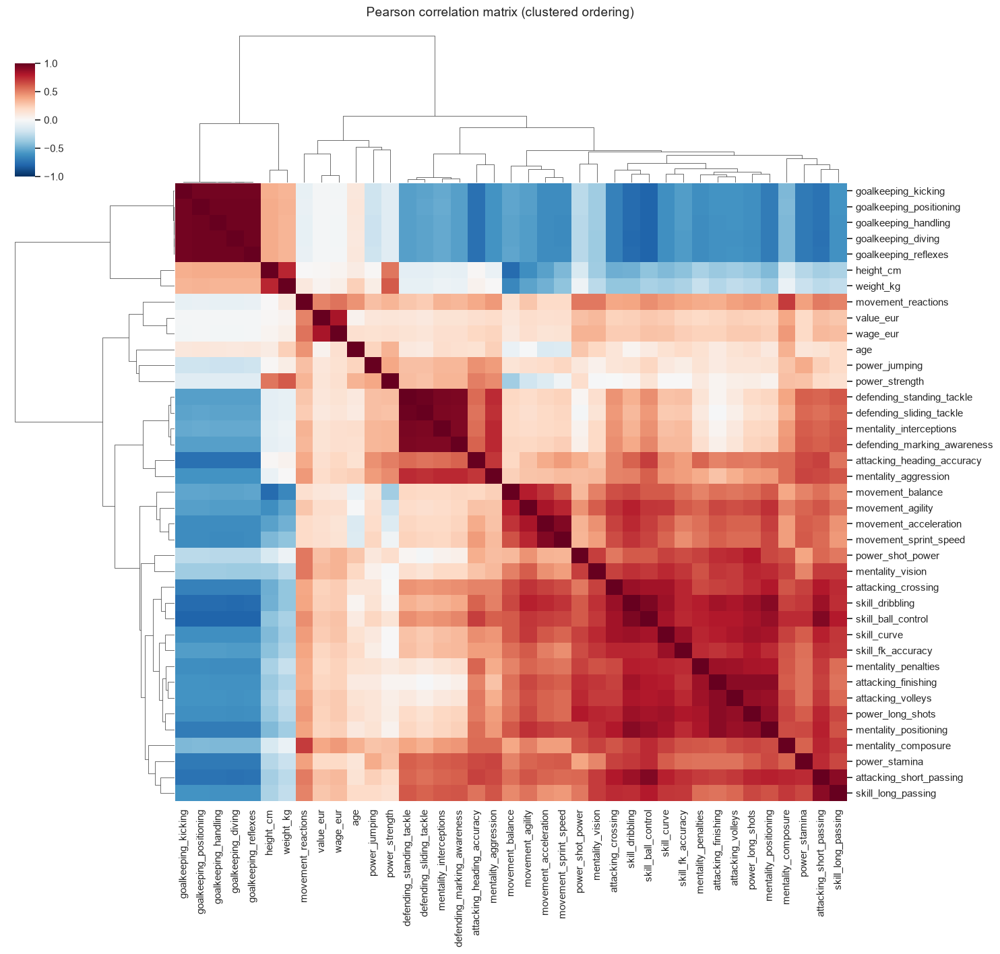

Strongest positive pairs:


,,pearson,spearman,|diff|
defending_standing_tackle,defending_sliding_tackle,0.977,0.972,0.005
goalkeeping_diving,goalkeeping_reflexes,0.974,0.327,0.647
goalkeeping_handling,goalkeeping_reflexes,0.972,0.331,0.640
goalkeeping_diving,goalkeeping_handling,0.972,0.324,0.647
goalkeeping_positioning,goalkeeping_reflexes,0.971,0.320,0.651
goalkeeping_diving,goalkeeping_positioning,0.971,0.324,0.648
goalkeeping_handling,goalkeeping_positioning,0.971,0.322,0.649
goalkeeping_kicking,goalkeeping_reflexes,0.969,0.325,0.644


Strongest negative pairs:


pearson  spearman  |diff|
skill_ball_control goalkeeping_diving        -0.804    -0.281   0.523
                   goalkeeping_handling      -0.802    -0.274   0.528
                   goalkeeping_reflexes      -0.802    -0.272   0.530
                   goalkeeping_kicking       -0.799    -0.265   0.534
                   goalkeeping_positioning   -0.798    -0.274   0.525
skill_dribbling    goalkeeping_diving        -0.775    -0.292   0.483

Largest Pearson-vs-Spearman disagreement:


pearson  spearman  |diff|
goalkeeping_positioning goalkeeping_reflexes       0.971     0.320   0.651
goalkeeping_handling    goalkeeping_positioning    0.971     0.322   0.649
goalkeeping_diving      goalkeeping_positioning    0.971     0.324   0.648
                        goalkeeping_handling       0.972     0.324   0.647
                        goalkeeping_reflexes       0.974     0.327   0.647
                        goalkeeping_kicking        0.968     0.324   0.645

Share of feature pairs with |r| > 0.7: 8.9%


In [5]:
pearson = df_raw.corr(method="pearson")
spearman = df_raw.corr(method="spearman")

# clustered heatmap: rows/columns are reordered so that correlated features sit together
g = sns.clustermap(pearson, cmap="RdBu_r", vmin=-1, vmax=1, figsize=(15, 14), method="average",
                   xticklabels=True, yticklabels=True, cbar_pos=(0.02, 0.83, 0.02, 0.12))
g.fig.suptitle("Pearson correlation matrix (clustered ordering)", y=1.01, fontsize=14)
plt.show()

upper = np.triu(np.ones(pearson.shape, bool), 1)
pairs = pearson.where(upper).stack().rename("pearson").to_frame()
pairs["spearman"] = spearman.where(upper).stack()
pairs["|diff|"] = (pairs.pearson - pairs.spearman).abs()
print("Strongest positive pairs:"); display(pairs.sort_values("pearson", ascending=False).head(8))
print("Strongest negative pairs:"); display(pairs.sort_values("pearson").head(6))
print("Largest Pearson-vs-Spearman disagreement:"); display(pairs.sort_values("|diff|", ascending=False).head(6))
print(f"Share of feature pairs with |r| > 0.7: {(pairs.pearson.abs() > .7).mean():.1%}")

🔎 **What the correlations tell us**
* **Massive redundancy.** Standing tackle ↔ sliding tackle: r = 0.98; the five goalkeeping ratings: r ≈ 0.97 with each other; 8.9% of all 741 feature pairs have |r| > 0.7. The clustered heatmap shows clear **blocks**: goalkeeping; defending (tackles, marking, interceptions, aggression); technical/attacking (ball control, dribbling, passing, shooting, vision…); pace (acceleration, sprint speed, agility); body (height, weight, strength); and money (value, wage, with reactions).
* **The strongest negative correlations** (ball control ↔ goalkeeping ≈ −0.80) are not football truths ("better ball control makes you a worse goalkeeper"); they reflect **two populations**: goalkeepers have high goalkeeping and low outfield ratings, outfield players the opposite.
* **Pearson vs. Spearman — a striking disagreement.** For goalkeeping pairs, Pearson ≈ 0.97 but Spearman ≈ 0.32. Pearson is dominated by the *between-group* difference (≈ 65 vs. ≈ 10); Spearman, based on ranks, is dominated by the 89% outfield players, whose goalkeeping ratings are **filler values with almost no mutual correlation** (we verify this in Section 4.9: r ≈ 0.06 within outfield players). The same number ("correlation") answers two different questions here — a warning for any analysis that mixes populations (a Simpson-type effect).

## 2.3 Distribution analysis — histograms, boxplots, skewness, kurtosis
* **Skewness** $= \mathbb{E}[(X-\mu)^3]/\sigma^3$ (0 = symmetric; negative = long *left* tail).
* **Excess kurtosis** $= \mathbb{E}[(X-\mu)^4]/\sigma^4 - 3$ (0 = Gaussian tails; large positive = heavy tails / extreme values; negative = flat or multi-modal).

Histograms are split by **goalkeepers (orange)** and **outfield players (blue)** because, as we will see, this single split explains most of the shape of every distribution.

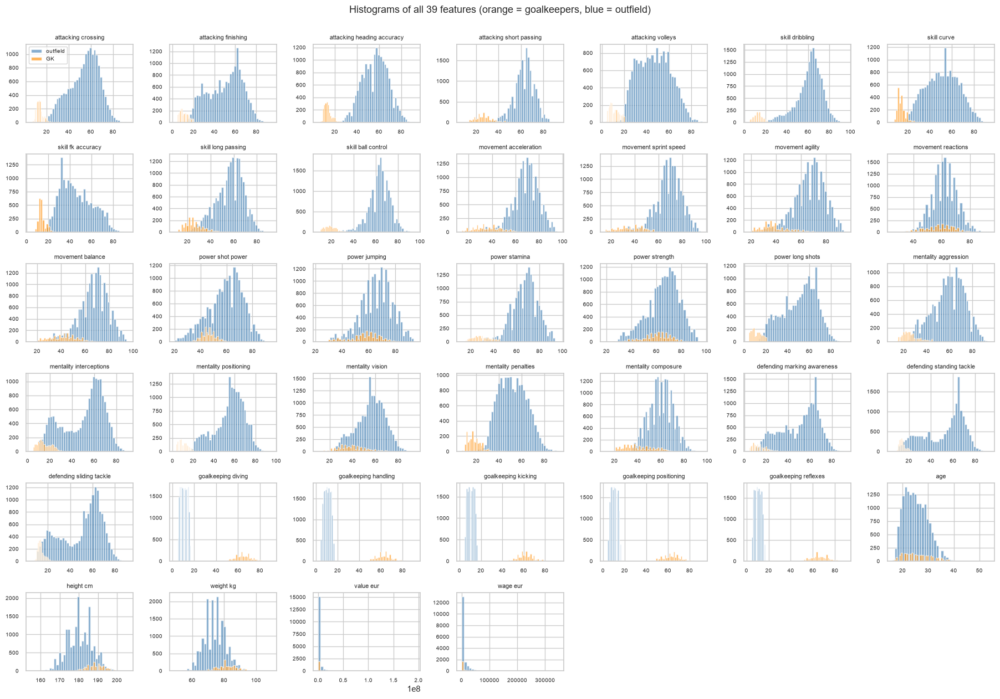

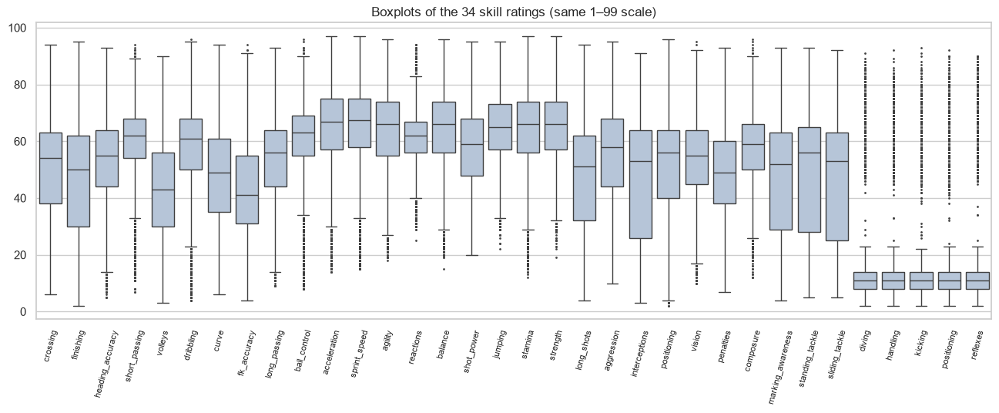

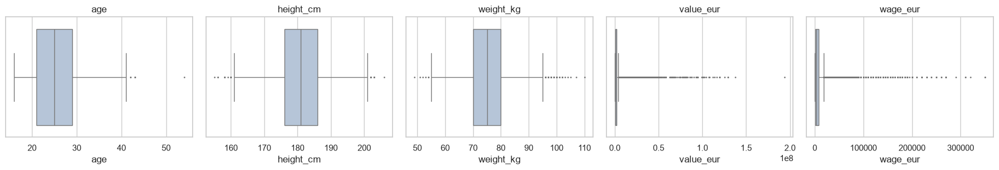

,skewness,excess_kurtosis,IQR_outliers_%
value_eur,8.188,97.929,11.654
wage_eur,6.472,63.051,12.488
goalkeeping_positioning,2.478,4.685,11.091
goalkeeping_reflexes,2.466,4.562,11.096
goalkeeping_kicking,2.444,4.500,11.112
goalkeeping_diving,2.454,4.491,11.091
goalkeeping_handling,2.446,4.476,11.091
skill_ball_control,-1.366,1.319,11.508
attacking_short_passing,-1.177,1.064,9.344
movement_sprint_speed,-0.936,0.720,4.693


IQR 'outliers' on goalkeeping_diving: 2,127; of them goalkeepers: 2,124


In [6]:
def plot_hist_grid(data, title, ncols=7, hue=None):
    cols = data.columns; nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.1 * nrows))
    for ax, col in zip(axes.ravel(), cols):
        if hue is None:
            ax.hist(data[col], bins=40, color="steelblue")
        else:
            for grp, color in [("outfield", "steelblue"), ("GK", "darkorange")]:
                ax.hist(data[col][hue == grp], bins=40, color=color, alpha=.65, label=grp)
        ax.set_title(col.replace("_", " "), fontsize=8); ax.tick_params(labelsize=7)
    for ax in axes.ravel()[len(cols):]: ax.axis("off")
    if hue is not None: axes.ravel()[0].legend(fontsize=7)
    fig.suptitle(title, y=1.0, fontsize=13); plt.tight_layout(); plt.show()

gk_flag = np.where(df.pos_group == "GK", "GK", "outfield")
plot_hist_grid(df_raw, "Histograms of all 39 features (orange = goalkeepers, blue = outfield)", hue=gk_flag)

# Boxplots: the 34 ratings share the same 1-99 scale, so one figure compares them directly
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=df_raw[SKILL_ATTRS], ax=ax, fliersize=1, color="lightsteelblue")
ax.set_xticklabels([c.split("_", 1)[1] for c in SKILL_ATTRS], rotation=75, fontsize=8)
ax.set_title("Boxplots of the 34 skill ratings (same 1–99 scale)"); plt.show()
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, col in zip(axes, PHYSICAL + MONEY):
    sns.boxplot(x=df_raw[col], ax=ax, fliersize=1, color="lightsteelblue"); ax.set_title(col)
plt.tight_layout(); plt.show()

def iqr_outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return 100 * ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

shape_table = pd.DataFrame({"skewness": df_raw.apply(stats.skew), "excess_kurtosis": df_raw.apply(stats.kurtosis),
                            "IQR_outliers_%": df_raw.apply(iqr_outlier_share)})
display(shape_table.sort_values("excess_kurtosis", ascending=False))
gk_attr_outliers = (df_raw["goalkeeping_diving"] > df_raw["goalkeeping_diving"].quantile(.75) +
                    1.5 * (df_raw["goalkeeping_diving"].quantile(.75) - df_raw["goalkeeping_diving"].quantile(.25)))
print(f"IQR 'outliers' on goalkeeping_diving: {gk_attr_outliers.sum():,}; of them goalkeepers: "
      f"{(gk_attr_outliers & (df.pos_group == 'GK')).sum():,}")

🔎 **What the distributions tell us**
* **Money is extremely heavy-tailed:** `value_eur` skewness 8.2, excess kurtosis 98; `wage_eur` 6.5 / 63. The median value is €975k while the maximum (Mbappé) is €194M — 200× the median. Without a transformation, a few superstars would dominate every variance-based method.
* **Goalkeeping ratings are bimodal** (two separate humps: outfield ≈ 10, goalkeepers ≈ 65): skewness ≈ 2.5, kurtosis ≈ 4.5. The 1.5·IQR rule flags 2,127 "outliers" on `goalkeeping_diving` — of which **2,124 are goalkeepers**. The rule is not finding outliers; it is finding a **second population**. This is the clearest example in the dataset of why "rare on one feature" ≠ "anomalous".
* **Outfield skills are left-skewed** (ball control −1.37, short passing −1.18, dribbling −1.17): most players are competent professionals and the long tail is on the *low* side — goalkeepers again, plus a few weak technical defenders. The 11% IQR-outliers on ball control / dribbling are, again, mostly goalkeepers.
* **Defending ratings are bimodal / flat** (negative kurtosis down to −1.3): defenders and defensive midfielders around 60–70, attackers around 20–40. Position, not noise, shapes the distribution.
* **Physical features are close to Gaussian** (height: skew ≈ 0, kurtosis −0.3; weight: 0.24 / 0.06). These are the only features for which a Z-score rule is well-founded.
* **Discreteness:** ratings are integers (≈ 86 distinct values per rating), height/weight are integers; this creates ties that affect nearest-neighbour methods.

## 2.4 Outlier exploration — heavy tails, extreme values, noise, measurement artifacts, data-entry problems

In [7]:
show_cols = ["short_name", "age", "club_name", "player_positions", "overall"]
print("Most valuable players:");  display(df.nlargest(5, "value_eur")[show_cols + ["value_eur"]])
print("Highest wages:");          display(df.nlargest(5, "wage_eur")[show_cols + ["wage_eur"]])
print("Oldest players:");         display(df.nlargest(4, "age")[show_cols])
print("Shortest / tallest:");     display(pd.concat([df.nsmallest(3, "height_cm"), df.nlargest(3, "height_cm")])[show_cols + ["height_cm", "weight_kg"]])

# Measurement artifacts: discreteness, filler values, rounding
print(f"Distinct values per rating (integers 1-99): median {df_raw[SKILL_ATTRS].nunique().median():.0f}")
outfield = df.pos_group != "GK"
print("Goalkeeping ratings of OUTFIELD players (filler values, not measurements):")
display(df_raw.loc[outfield, GOALKEEPING].describe().T[["mean", "std", "min", "50%", "max"]])
print("Outfield players with the highest goalkeeping ratings:")
display(df.loc[outfield].assign(gk_mean=df_raw.loc[outfield, GOALKEEPING].mean(1)).nlargest(4, "gk_mean")[show_cols + ["gk_mean"]])
print("Goalkeepers with the highest finishing:")
display(df.loc[~outfield].nlargest(4, "attacking_finishing")[show_cols + ["attacking_finishing"]])
print(f"Share of values divisible by 1000 (value_eur): {(df_raw.value_eur % 1000 == 0).mean():.1%}; "
      f"distinct wage values: {df_raw.wage_eur.nunique()}")

checks = {"weight/height^2 (BMI) < 17": ((df_raw.weight_kg / (df_raw.height_cm / 100) ** 2) < 17).sum(),
          "BMI > 30": ((df_raw.weight_kg / (df_raw.height_cm / 100) ** 2) > 30).sum(),
          "age < 17": (df_raw.age < 17).sum(), "age > 40": (df_raw.age > 40).sum(),
          "wage = 500 (minimum)": (df_raw.wage_eur == df_raw.wage_eur.min()).sum()}
print(pd.Series(checks, name="count").to_string())

Most valuable players:


,short_name,age,club_name,player_positions,overall,value_eur
6,K. Mbappé,22,Paris Saint-Germain,"ST, LW",91,"194,000,000.000"
29,E. Haaland,20,Borussia Dortmund,ST,88,"137,500,000.000"
9,H. Kane,27,Tottenham Hotspur,ST,90,"129,500,000.000"
3,Neymar Jr,29,Paris Saint-Germain,"LW, CAM",91,"129,000,000.000"
4,K. De Bruyne,30,Manchester City,"CM, CAM",91,"125,500,000.000"


Highest wages:


,short_name,age,club_name,player_positions,overall,wage_eur
4,K. De Bruyne,30,Manchester City,"CM, CAM",91,"350,000.000"
11,K. Benzema,33,Real Madrid CF,"CF, ST",89,"350,000.000"
0,L. Messi,34,Paris Saint-Germain,"RW, ST, CF",93,"320,000.000"
14,Casemiro,29,Real Madrid CF,CDM,89,"310,000.000"
24,T. Kroos,31,Real Madrid CF,CM,88,"310,000.000"


Oldest players:


,short_name,age,club_name,player_positions,overall
16148,K. Miura,54,Yokohama FC,ST,59
387,G. Buffon,43,Parma,GK,80
3088,C. Lucchetti,43,Atlético Tucumán,GK,72
12189,S. Nakamura,43,Yokohama FC,"CAM, CF, RW",63


... (5 outputs left out)

,short_name,age,club_name,player_positions,overall,gk_mean
4568,P. Jagielka,38,Derby County,CB,70,33.800
23,L. Suárez,34,Atlético de Madrid,ST,88,30.600
6620,L. Veldwijk,29,Suwon FC,ST,68,28.400
4578,A. Tettey,35,Rosenborg BK,CDM,70,23.800


Goalkeepers with the highest finishing:


,short_name,age,club_name,player_positions,overall,attacking_finishing
700,M. Hitz,33,Borussia Dortmund,GK,78,27
2958,A. Bodart,23,Standard de Liège,GK,73,22
6772,G. Castellón,27,CD Huachipato,GK,68,21
7782,N. Veloso,34,Club Deportivo Palestino,GK,67,21


Share of values divisible by 1000 (value_eur): 100.0%; distinct wage values: 133
weight/height^2 (BMI) < 17       2
BMI > 30                         2
age < 17                        20
age > 40                        13
wage = 500 (minimum)          2276


🔎 **Outlier exploration — what is noise, what is artifact, what is real?**

| Type | Evidence | Interpretation |
|---|---|---|
| **Heavy tails (real)** | Mbappé €194M (median €975k); De Bruyne and Benzema €350k/week (median €3k) | Genuine superstars: legitimate extremes, the *point* of a heavy tail. |
| **Extreme but real values** | Kazuyoshi Miura, **54 years old** (Yokohama FC); 155 cm and 206 cm players | Miura really is the oldest professional footballer in the world — a famous, legitimate anomaly. Heights are plausible. |
| **Measurement artifacts — filler values** | Outfield goalkeeping ratings: mean 10.3, sd 3.0, max ≈ 33–38 | Not abilities but placeholders. The few "high" ones (Jagielka 33.8, Suárez 30.6) may reflect EA giving a small bonus to players who once went in goal — or noise. They are invisible to a Z-score on all players. |
| **Artifacts — rounding, floors, censoring** | 100% of values are multiples of €1,000; only 133 distinct wages; **2,276 players at the €500 wage floor** | Money is generated by a game formula and rounded; the floor is a censoring "wall" (like a top-code) that creates an artificial dense spike. |
| **Artifacts — structural missingness** | Veterans 40+ with no value; unlicensed leagues with no club | Caused by game rules/licensing, not by the players. |
| **Possible data-entry problems** | 2 players with BMI < 17, 2 with BMI > 30; goalkeepers with finishing 27 (Hitz) | Rare combinations worth checking; BMI > 30 is plausible for very muscular players (Akinfenwa, 110 kg, famous for being the strongest player in the FIFA games), BMI < 17 is suspicious. |

**Decision:** no row is deleted for being extreme — detecting such rows is the goal of Section 5. We only drop rows with missing wage (no club) and handle the money tails with a log transform.

## 2.5 Preprocessing decisions
1. **Rows:** drop the 61 players without a club (no wage, no value — missing because of licensing). Keep the 13 veterans aged 40+ whose value is missing because the game assigns no transfer value to them; we encode "no market value" as the minimum observed value (€9,000). *This is a modeling choice with consequences — the imputed value itself makes these players look extreme (Section 6).*
2. **`log10` transform of `value_eur` and `wage_eur`.** Money is multiplicative (the difference between €1M and €2M matters like the one between €50M and €100M); the log removes the extreme skew so that a handful of superstars does not dominate variance-based methods. It is monotone, so the ranking of players is unchanged.
3. **No transform for ratings.** They are bounded (1–99) and their skewness is moderate; their non-Gaussian shape comes from the mixture of populations, which a transform cannot fix.
4. **Standardization** (zero mean, unit variance) of all 39 features. Height (cm), weight (kg), money (log €) and ratings live on different scales; every method below is variance- or distance-based.
5. We keep two alternative versions — **raw** and **standardized without log** — to measure how much the conclusions depend on these choices (Section 6.2).

,skew_before,skew_after_log,kurt_before,kurt_after_log
value_eur,8.188,0.549,97.929,0.933
wage_eur,6.472,0.472,63.051,-0.466


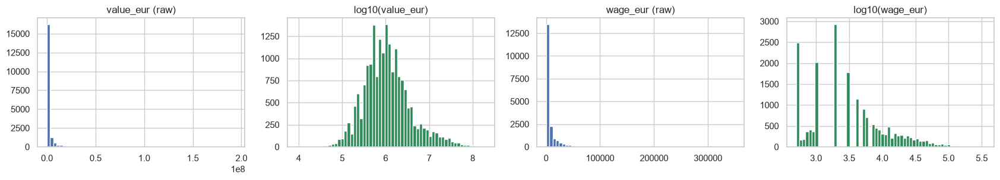

In [8]:
LOG_FEATURES = MONEY
df_log = df_raw.copy()
df_log[LOG_FEATURES] = np.log10(df_log[LOG_FEATURES])

X = StandardScaler().fit_transform(df_log)                    # main analysis matrix (n x 39)
X_raw_std = StandardScaler().fit_transform(df_raw)            # standardized, no log
X_raw = df_raw.values                                         # completely raw
is_gk_arr = (df.pos_group == "GK").values

after = pd.DataFrame({"skew_before": df_raw[MONEY].apply(stats.skew), "skew_after_log": df_log[MONEY].apply(stats.skew),
                      "kurt_before": df_raw[MONEY].apply(stats.kurtosis), "kurt_after_log": df_log[MONEY].apply(stats.kurtosis)})
display(after)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2))
for i, col in enumerate(MONEY):
    axes[2*i].hist(df_raw[col], bins=60); axes[2*i].set_title(f"{col} (raw)")
    axes[2*i+1].hist(df_log[col], bins=60, color="seagreen"); axes[2*i+1].set_title(f"log10({col})")
plt.tight_layout(); plt.show()

🔎 After `log10`, the skewness of value and wage drops from 8.2 / 6.5 to ≈ 0.5, and kurtosis from 98 / 63 to < 1: the money features become almost symmetric. Superstars are still at the top of the distribution (the transform is monotone) — they are simply no longer 25 standard deviations away from everyone else. The histograms show that the log-wage has a visible spike at log10(500) ≈ 2.7 — the wage floor — which no transformation can remove.

# 3. Dimensionality Reduction (20%)
## 3.1 Principal Component Analysis
📘 **Intuition.** PCA finds orthogonal directions of maximum variance: $w_1 = \arg\max_{\|w\|=1} w^\top\Sigma w$, the leading eigenvector of the covariance (here: correlation) matrix $\Sigma = V\Lambda V^\top$. The explained-variance ratio of component $j$ is $\lambda_j/\sum_i\lambda_i$. The first $k$ components give the best rank-$k$ linear approximation (Eckart–Young), so the **information lost** by keeping $k$ components is exactly $\sum_{j>k}\lambda_j / \sum_j \lambda_j$.

**Assumptions & limitations:** linear relationships; "large variance = important"; sensitive to scaling (we standardize) and to outliers (squared deviations). Components are linear mixtures of all features, so interpretation relies on the loadings.

,eigenvalue,explained_var_ratio,cumulative
PC1,19.796,0.508,0.508
PC2,5.152,0.132,0.640
PC3,4.150,0.106,0.746
PC4,2.150,0.055,0.801
PC5,1.347,0.035,0.836
PC6,1.068,0.027,0.863
PC7,0.619,0.016,0.879
PC8,0.490,0.013,0.892
PC9,0.373,0.010,0.901
PC10,0.341,0.009,0.910


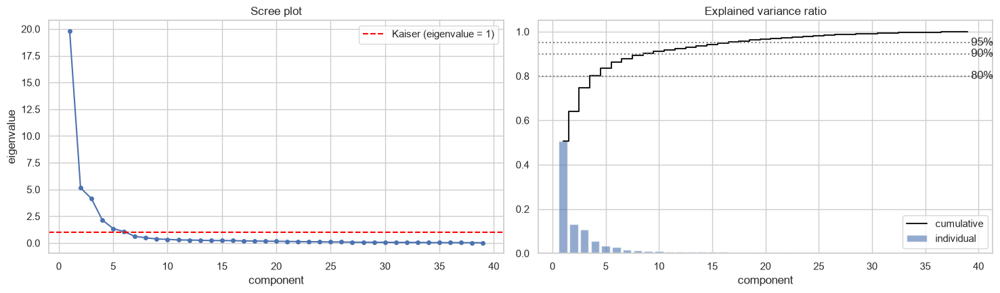

Auto-summary: PC1 50.8%, PC1+2 64.0%, PC1-3 74.6%. Components for 80/90/95%: 4/9/17. Kaiser keeps 6.
Information lost: 2 PCs 36.0%, 3 PCs 25.4%, 9 PCs 9.9%


In [9]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X)
evr = pca_full.explained_variance_ratio_; cum = np.cumsum(evr); eig = pca_full.explained_variance_
pc_names = [f"PC{i+1}" for i in range(n_features)]
display(pd.DataFrame({"eigenvalue": eig, "explained_var_ratio": evr, "cumulative": cum}, index=pc_names).head(12))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(range(1, n_features + 1), eig, "o-", ms=4); ax[0].axhline(1, color="red", ls="--", label="Kaiser (eigenvalue = 1)")
ax[0].set(title="Scree plot", xlabel="component", ylabel="eigenvalue"); ax[0].legend()
ax[1].bar(range(1, n_features + 1), evr, alpha=.6, label="individual")
ax[1].step(range(1, n_features + 1), cum, where="mid", color="k", label="cumulative")
for thr in (.8, .9, .95): ax[1].axhline(thr, ls=":", color="gray"); ax[1].text(n_features + .3, thr, f"{int(thr*100)}%", va="center")
ax[1].set(title="Explained variance ratio", xlabel="component"); ax[1].legend()
plt.tight_layout(); plt.show()

k80, k90, k95 = (int(np.argmax(cum >= t)) + 1 for t in (.8, .9, .95))
k_kaiser = int((eig > 1).sum())
print(f"Auto-summary: PC1 {evr[0]:.1%}, PC1+2 {cum[1]:.1%}, PC1-3 {cum[2]:.1%}. "
      f"Components for 80/90/95%: {k80}/{k90}/{k95}. Kaiser keeps {k_kaiser}.")

recon = [1 - cum[k - 1] for k in range(1, n_features + 1)]     # lost variance fraction (standardized data)
print(f"Information lost: 2 PCs {recon[1]:.1%}, 3 PCs {recon[2]:.1%}, {k90} PCs {recon[k90-1]:.1%}")

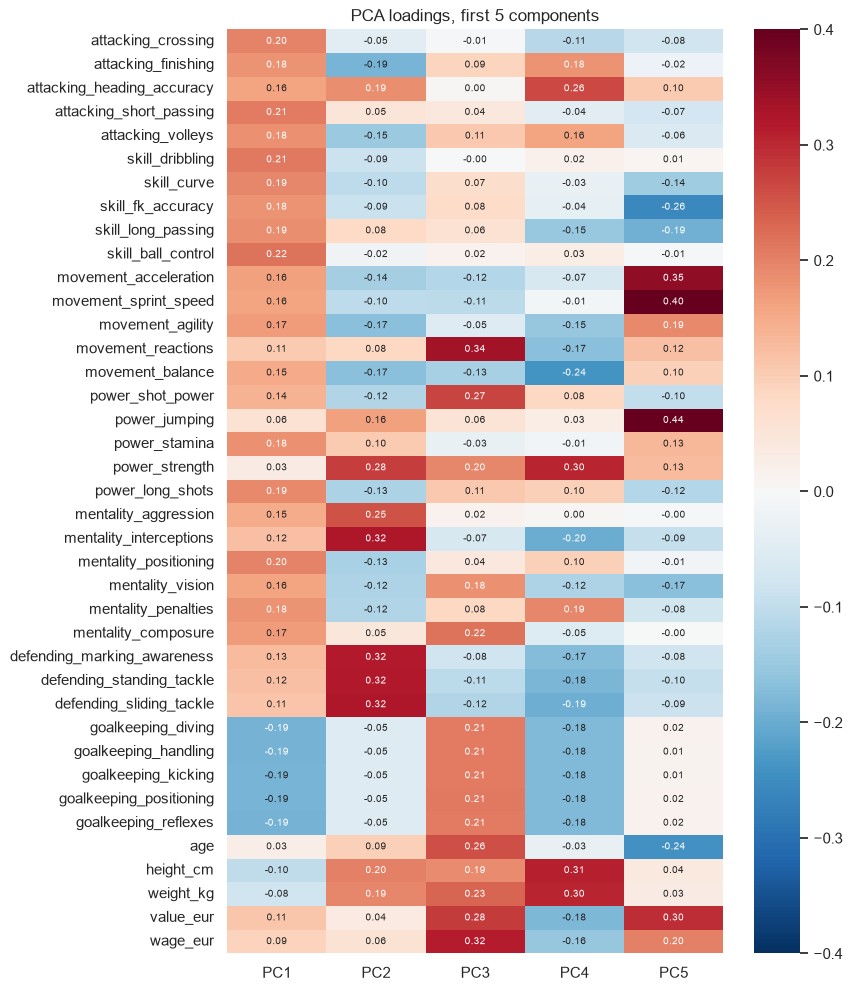

Auto-summary — strongest loadings per component:
  PC1 [50.8%]  (+): skill_ball_control, skill_dribbling, attacking_short_passing, mentality_positioning   (−): goalkeeping_diving, goalkeeping_handling, goalkeeping_reflexes, goalkeeping_kicking
  PC2 [13.2%]  (+): defending_sliding_tackle, mentality_interceptions, defending_standing_tackle, defending_marking_awareness   (−): attacking_finishing, movement_agility, movement_balance, attacking_volleys
  PC3 [10.6%]  (+): movement_reactions, wage_eur, value_eur, power_shot_power   (−): movement_balance, defending_sliding_tackle, movement_acceleration, defending_standing_tackle
  PC4 [5.5%]  (+): height_cm, weight_kg, power_strength, attacking_heading_accuracy   (−): movement_balance, mentality_interceptions, defending_sliding_tackle, defending_standing_tackle
  PC5 [3.5%]  (+): power_jumping, movement_sprint_speed, movement_acceleration, value_eur   (−): skill_fk_accuracy, age, skill_long_passing, mentality_vision


In [10]:
loadings = pd.DataFrame(pca_full.components_.T, index=FEATURES, columns=pc_names)
# fix the sign of each component so that its largest loading is positive (PCA signs are arbitrary)
loadings = loadings * np.sign(loadings.apply(lambda c: c[c.abs().idxmax()]))
fig, ax = plt.subplots(figsize=(8, 12))
sns.heatmap(loadings.iloc[:, :5], annot=True, fmt=".2f", cmap="RdBu_r", vmin=-.4, vmax=.4, ax=ax, annot_kws={"size": 7})
ax.set_title("PCA loadings, first 5 components"); plt.show()

print("Auto-summary — strongest loadings per component:")
for pc in pc_names[:5]:
    s = loadings[pc].sort_values()
    print(f"  {pc} [{evr[pc_names.index(pc)]:.1%}]  (+): {', '.join(s.index[::-1][:4])}   (−): {', '.join(s.index[:4])}")

🔎 **Interpreting the principal components**
* **PC1 (50.8%) — "goalkeeper vs. outfield player".** Large positive loadings on technical outfield skills (ball control, dribbling, short passing, positioning), large negative loadings on the five goalkeeping ratings. Half of all variance in the dataset is explained by one fact: whether the player is a goalkeeper. This is a consequence of the mixture of two populations, amplified by the filler values.
* **PC2 (13.2%) — "defender vs. attacker".** Positive: sliding/standing tackle, interceptions, marking; negative: finishing, volleys, agility, balance. This is the main *football* axis among outfield players.
* **PC3 (10.6%) — "established quality / status".** Positive: reactions, wage, value, shot power (high-level, well-paid players); negative: balance and acceleration (small, agile, often young players).
* **PC4 (5.5%) — "body size".** Height, weight, strength, heading vs. balance.
* **PC5 (3.5%) — "young athlete vs. experienced playmaker".** Jumping, sprint speed, acceleration, value vs. free-kick accuracy, age, long passing, vision.

**Effect of correlated variables:** each correlated block collapses into roughly one component (the 5 goalkeeping ratings → PC1; the 4–5 defensive ratings → PC2). The eigenvalues fall off steeply: 19.8, 5.2, 4.2, 2.2, then < 1.4 — far from the 39 equal eigenvalues of uncorrelated data.

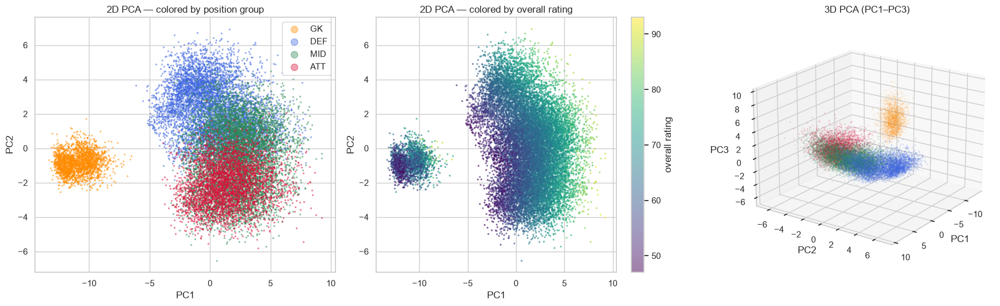

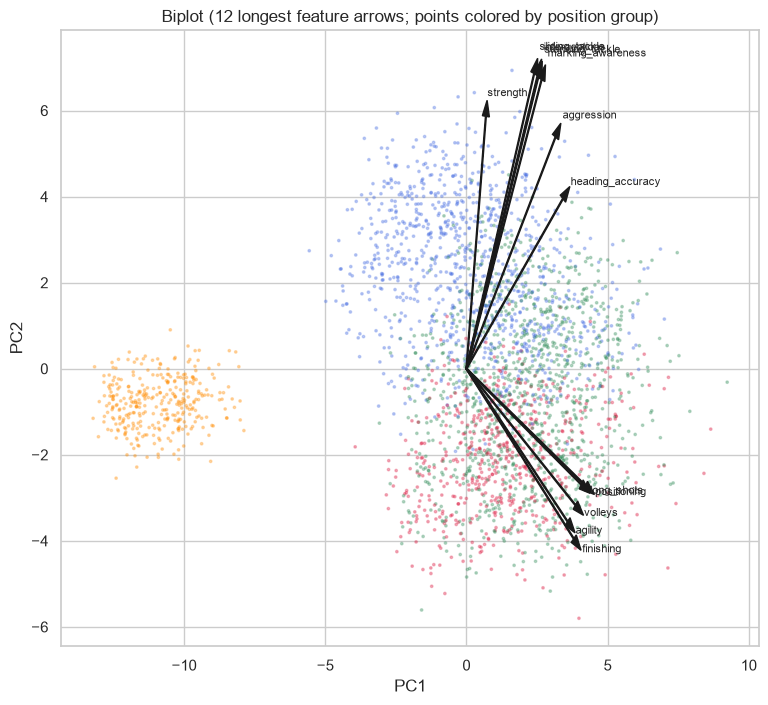

In [11]:
Z = X @ loadings.values                                         # scores with the sign convention above
POS_COLORS = {"GK": "darkorange", "DEF": "royalblue", "MID": "seagreen", "ATT": "crimson"}
pos_c = df.pos_group.map(POS_COLORS).values

fig = plt.figure(figsize=(18, 5.5))
ax1 = fig.add_subplot(1, 3, 1)
for grp, col in POS_COLORS.items():
    m = (df.pos_group == grp).values; ax1.scatter(Z[m, 0], Z[m, 1], s=2, c=col, alpha=.4, label=grp)
ax1.legend(markerscale=6); ax1.set(title="2D PCA — colored by position group", xlabel="PC1", ylabel="PC2")
ax2 = fig.add_subplot(1, 3, 2)
sc = ax2.scatter(Z[:, 0], Z[:, 1], c=df.overall, s=2, cmap="viridis", alpha=.5)
plt.colorbar(sc, ax=ax2, label="overall rating"); ax2.set(title="2D PCA — colored by overall rating", xlabel="PC1", ylabel="PC2")
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.scatter(Z[:, 0], Z[:, 1], Z[:, 2], c=pos_c, s=1, alpha=.4)
ax3.set(title="3D PCA (PC1–PC3)", xlabel="PC1", ylabel="PC2", zlabel="PC3"); ax3.view_init(20, 35)
plt.tight_layout(); plt.show()

# Biplot with the 12 features that have the longest arrows in the PC1-PC2 plane
arrow_len = np.hypot(loadings.PC1, loadings.PC2); top_f = arrow_len.sort_values(ascending=False).index[:12]
idx = rng.choice(n_samples, 3000, replace=False)
plt.figure(figsize=(9, 8)); plt.scatter(Z[idx, 0], Z[idx, 1], s=3, c=pos_c[idx], alpha=.3)
scale = np.abs(Z[idx, :2]).max() * 1.6
for f in top_f:
    plt.arrow(0, 0, loadings.loc[f, "PC1"] * scale, loadings.loc[f, "PC2"] * scale, color="k", width=.03, head_width=.25)
    plt.text(loadings.loc[f, "PC1"] * scale * 1.08, loadings.loc[f, "PC2"] * scale * 1.08, f.split("_", 1)[-1], fontsize=8)
plt.title("Biplot (12 longest feature arrows; points colored by position group)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

🔎 **What the projections show**
* **Two clearly separated clouds along PC1**: goalkeepers (left) and outfield players (right), with an empty gap between them. This is the only *natural* cluster structure in the data.
* Inside the outfield cloud, **PC2 orders positions**: defenders at the top, midfielders in the middle, attackers at the bottom — but as overlapping, continuous bands, not as separated groups.
* Coloring by `overall` shows that quality increases along a diagonal direction — i.e. "how good" is mixed into the first components and will influence clustering.
* In 3D, PC3 lifts the goalkeepers further away; the outfield cloud is a single elongated mass.
* The biplot confirms the axes: technical arrows point right (outfield), defensive arrows up, finishing/agility down, goalkeeping arrows left.

### 3.2 Is the reduced representation more effective than the original one?
We test this empirically: cluster the players with K-Means in the full 39-D space and in the first $k$ principal components, and compare the partitions (ARI) and runtimes. We also compute two redundancy indicators: the **participation ratio** $(\sum\lambda)^2/\sum\lambda^2$ ("effective number of dimensions") and the **condition number** $\lambda_{max}/\lambda_{min}$.

In [12]:
def kmeans_labels(data, k=4, seed=RANDOM_STATE):
    return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(data)

t0 = time.perf_counter(); lab_full = kmeans_labels(X); t_full = time.perf_counter() - t0
rows = [{"PCs kept": n_features, "variance kept": 1.0, "ARI vs full space": 1.0, "runtime (s)": t_full}]
for k in [2, 3, 5, k80, k90]:
    t0 = time.perf_counter(); lab_k = kmeans_labels(Z[:, :k]); t_k = time.perf_counter() - t0
    rows.append({"PCs kept": k, "variance kept": cum[k-1], "ARI vs full space": adjusted_rand_score(lab_full, lab_k), "runtime (s)": t_k})
display(pd.DataFrame(rows))
participation_ratio = eig.sum() ** 2 / (eig ** 2).sum()
print(f"Effective dimensionality (participation ratio): {participation_ratio:.2f} of {n_features}")
print(f"Condition number of the correlation matrix: {eig.max() / eig.min():,.0f}")

,PCs kept,variance kept,ARI vs full space,runtime (s)
0,39,1.000,1.000,0.277
1,2,0.640,0.807,0.081
2,3,0.746,0.851,0.079
3,5,0.836,0.981,0.097
4,4,0.801,0.962,0.096
5,9,0.901,0.991,0.111


Effective dimensionality (participation ratio): 3.42 of 39
Condition number of the correlation matrix: 972


🔎 **How many components? How much is lost? Is the reduced data "better"?**
* **4 components explain 80%**, 9 explain 90%, 17 explain 95%; the Kaiser criterion (eigenvalue > 1) keeps 6. With 2 components we lose 36% of the variance; with 3, 25%.
* The **participation ratio is 3.4 out of 39** and the condition number ≈ 970: the original 39 features are **highly redundant** — they behave like ~4 effective dimensions (GK-vs-outfield, defence-vs-attack, quality/status, body size).
* **Clustering on 5 PCs reproduces the full-space K-Means almost exactly (ARI = 0.98)** and on 9 PCs (ARI = 0.99), at about a third of the runtime. Two PCs already give ARI = 0.81.
* **Conclusion:** yes — a 5–9 component representation is *more effective* than the original: it keeps the structure that matters, removes redundancy and low-variance noise (e.g. the uncorrelated filler noise of goalkeeping ratings lives in the last components), and is faster. The computational gain is small here (39 features); the main gain is **interpretability** — five named axes instead of 39 overlapping ratings. A 2-D view is enough to *see* the GK/outfield split, but not to represent outfield roles faithfully.

### 3.3 Comparison with a non-linear method: t-SNE
📘 **t-SNE** turns distances into neighbor probabilities (Gaussian kernel in the original space, heavy-tailed Student-t in 2-D) and minimizes the KL divergence between them. It **preserves local neighborhoods** but not global distances; it is stochastic and expensive ($O(n\log n)$–$O(n^2)$), so we use a random sample of 3,000 players and two seeds.
We compare with two measures: **trustworthiness** (are the 10 nearest neighbors in 2-D also neighbors in 39-D? — local structure) and **Spearman correlation between all pairwise distances** in 39-D and 2-D (global structure).

,method,runtime (s),trustworthiness (local),distance corr. (global)
0,PCA,0.003,0.899,0.910
1,t-SNE (seed 0),10.649,0.981,0.811
2,t-SNE (seed 1),10.924,0.981,0.811


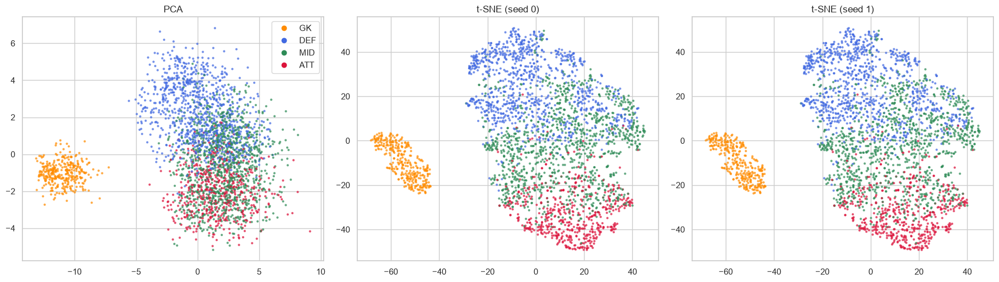

In [13]:
sample_idx = rng.choice(n_samples, 3000, replace=False)
Xs = X[sample_idx]; d_orig = pdist(Xs)
embeddings, results = {}, []
t0 = time.perf_counter(); emb = PCA(2).fit_transform(Xs); t = time.perf_counter() - t0
embeddings["PCA"] = emb
results.append(("PCA", t, trustworthiness(Xs, emb, n_neighbors=10), stats.spearmanr(d_orig, pdist(emb))[0]))
for seed in (0, 1):
    t0 = time.perf_counter(); emb = TSNE(2, perplexity=30, init="pca", random_state=seed).fit_transform(Xs); t = time.perf_counter() - t0
    embeddings[f"t-SNE (seed {seed})"] = emb
    results.append((f"t-SNE (seed {seed})", t, trustworthiness(Xs, emb, n_neighbors=10), stats.spearmanr(d_orig, pdist(emb))[0]))
display(pd.DataFrame(results, columns=["method", "runtime (s)", "trustworthiness (local)", "distance corr. (global)"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, (name, emb) in zip(axes, embeddings.items()):
    ax.scatter(emb[:, 0], emb[:, 1], c=pos_c[sample_idx], s=4, alpha=.6); ax.set_title(name)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=g) for g, c in POS_COLORS.items()]
axes[0].legend(handles=handles); plt.tight_layout(); plt.show()

🔎 **PCA vs. t-SNE**

| Aspect | PCA | t-SNE |
|---|---|---|
| **Local structure** (trustworthiness) | 0.90 | **0.98** — neighbours are preserved better |
| **Global structure** (distance correlation) | **0.91** | 0.81 — global distances are distorted |
| **Cluster separation** | GK/outfield gap visible; positions as overlapping bands | GK island very clear; outfield shows "sub-islands" and position gradients that look more separated than they are |
| **Stability** | deterministic (up to sign) | different seeds → different layouts (same neighbourhoods) |
| **Computational cost** | ~0.002 s on 3,000 players | ~10 s on 3,000 players (we had to subsample) |
| **Interpretability** | axes = named combinations of features (loadings) | axes and inter-cluster distances have no meaning |
| **Redundancy** | measured explicitly (eigenvalues) | not quantified |

**Conclusion:** PCA is the method of choice to *understand* and compress the data; t-SNE is a useful complement to look at local neighbourhoods (e.g. players similar to a given player), but the apparent clumps inside the outfield cloud must not be read as evidence of clusters.

# 4. Clustering Analysis (20%)

📘 **Methods used**

| Method | Mathematical intuition | Main assumptions | Strengths | Weaknesses |
|---|---|---|---|---|
| **K-Means** | Minimizes the within-cluster sum of squares $\sum_k\sum_{x\in C_k}\|x-\mu_k\|^2$ by alternating *assign to nearest centroid* / *recompute means* (Lloyd). | Convex, roughly spherical clusters of similar size and spread; Euclidean distance meaningful; $k$ given. | Fast ($O(nkd)$ per iteration), simple, scalable. | Always returns $k$ clusters, even if none exist; sensitive to scaling, outliers, initialization; no non-convex shapes. |
| **Agglomerative (Ward)** | Bottom-up: start from single points and repeatedly merge the two clusters whose merge increases total within-cluster variance the least → a full hierarchy (dendrogram). | Ward: same variance criterion as K-Means. Other linkages: single (nearest pair → chaining), complete (farthest pair), average. | No need to fix $k$ beforehand; shows structure at every scale; deterministic. | $O(n^2)$ memory → fitted on a 5,000-player sample; greedy merges are never undone. |
| **DBSCAN** | Core point: ≥ `min_samples` points within radius `eps`; clusters = density-connected core points; the rest is **noise**. | Clusters are dense regions separated by *sparse gaps*; a single density level fits all clusters. | Arbitrary shapes, no $k$, explicit noise. | Very sensitive to `eps`; fails with varying density; distances concentrate in high dimensions. |
| **Gaussian Mixture (bonus)** | Data = mixture of $k$ Gaussians, fitted by EM; soft (probabilistic) membership; $k$ by BIC. | Ellipsoidal Gaussian clusters. | Different shapes and orientations; uncertainty of membership. | Gaussian assumption; many parameters in 34-D ($k\cdot d(d+3)/2$). |

**Plan.** (4.2) all players; (4.3–4.7) outfield players only — because the goalkeeper split turns out to be trivial; (4.8) "level vs. shape"; (4.9) clustering of the features themselves.

### 4.1 How do we evaluate a clustering without labels?
The assignment proposes the **average within-cluster variance relative to the global variance**:
$$\text{VR}=\frac{\sum_k\sum_{x\in C_k}\|x-\mu_k\|^2}{\sum_x\|x-\bar x\|^2}=1-R^2 .$$
**Is it suitable?** Only partially:
* ✅ Intuitive ("what fraction of the variance is *not* explained by the cluster labels"); good for comparing centroid-based partitions with the same $k$.
* ❌ It **decreases monotonically with $k$** (→ 0 when every point is its own cluster), so it cannot choose $k$ except via an elbow.
* ❌ It is exactly the K-Means objective → **biased in favour of K-Means**, and it penalizes correct non-convex clusters (DBSCAN).
* ❌ It ignores **separation** between clusters and is undefined for noise points.

**Alternatives we use as well:** the **silhouette** $s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$ (compactness *and* separation, in $[-1,1]$; > 0.5 = strong structure, < 0.25 = weak/artificial); **Davies–Bouldin** (lower = better); **Calinski–Harabasz** (between/within variance ratio, higher = better); **stability** (ARI between K-Means fitted on two different random halves — a real structure should be reproducible); and, *only for interpretation*, agreement with the known player positions (ARI/NMI) as an **external** validation.

In [14]:
def variance_ratio(data, labels):
    """Average within-cluster variance / global variance (DBSCAN noise label -1 excluded)."""
    mask = labels != -1; d, l = data[mask], labels[mask]
    within = sum(((d[l == c] - d[l == c].mean(0)) ** 2).sum() for c in np.unique(l))
    return within / ((d - d.mean(0)) ** 2).sum()

def evaluate_clustering(data, labels, name, sample_size=5000, seed=RANDOM_STATE):
    mask = labels != -1; n_cl = len(np.unique(labels[mask]))
    out = {"method": name, "n_clusters": n_cl, "noise_%": 100 * (~mask).mean()}
    if n_cl < 2:
        return {**out, "var_ratio": np.nan, "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    out["var_ratio"] = variance_ratio(data, labels)
    out["silhouette"] = silhouette_score(data[mask], labels[mask], sample_size=min(sample_size, mask.sum()), random_state=seed)
    out["davies_bouldin"] = davies_bouldin_score(data[mask], labels[mask])
    out["calinski_harabasz"] = calinski_harabasz_score(data[mask], labels[mask])
    return out

def kmeans_scan(data, k_values, label):
    rows, models = [], {}
    for k in k_values:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(data); models[k] = km
        row = evaluate_clustering(data, km.labels_, f"{label} k={k}")
        n = len(data)
        a = KMeans(k, n_init=5, random_state=1).fit(data[rng.choice(n, n // 2, replace=False)]).predict(data)
        b = KMeans(k, n_init=5, random_state=2).fit(data[rng.choice(n, n // 2, replace=False)]).predict(data)
        row["stability_ARI"] = adjusted_rand_score(a, b); rows.append(row)
    res = pd.DataFrame(rows).set_index("n_clusters")[["var_ratio", "silhouette", "davies_bouldin", "calinski_harabasz", "stability_ARI"]]
    fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
    for ax, col, better in zip(axes, ["var_ratio", "silhouette", "davies_bouldin", "stability_ARI"], ["elbow", "higher", "lower", "higher"]):
        ax.plot(res.index, res[col], "o-"); ax.set(title=f"{label}: {col} ({better} better)", xlabel="k")
    plt.tight_layout(); plt.show()
    return res, models

### 4.2 All players: is there a natural cluster structure?
We scan K-Means for $k=2,\dots,8$ and also run DBSCAN (`min_samples` = 2·d, `eps` from the knee of the k-distance curve; details in 4.5).

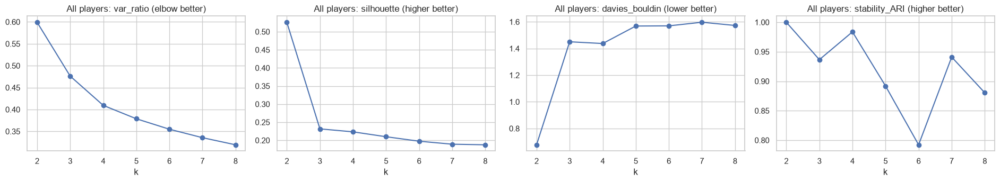

,var_ratio,silhouette,davies_bouldin,calinski_harabasz,stability_ARI
n_clusters,,,,,
2,0.599,0.526,0.678,"12,826.123",1.000
3,0.476,0.232,1.451,"10,543.712",0.937
4,0.409,0.223,1.437,"9,220.405",0.984
5,0.379,0.210,1.569,"7,860.496",0.892
6,0.355,0.198,1.570,"6,968.628",0.792
7,0.336,0.189,1.597,"6,324.938",0.941
8,0.319,0.188,1.573,"5,836.280",0.880


K-Means k=2 vs goalkeeper/outfield:


col_0,GK,outfield
row_0,,
0,0,17054
1,2124,0


ARI(k=2 clusters, GK flag) = 1.000

DBSCAN on all players (eps=3.94, min_samples=78):


col_0,GK,outfield
row_0,,
-1,9,52
0,0,17002
1,2115,0


In [15]:
km_all_df, km_all_models = kmeans_scan(X, range(2, 9), "All players")
display(km_all_df)
labels_km2 = km_all_models[2].labels_
print("K-Means k=2 vs goalkeeper/outfield:")
display(pd.crosstab(labels_km2, np.where(is_gk_arr, "GK", "outfield")))
print(f"ARI(k=2 clusters, GK flag) = {adjusted_rand_score(labels_km2, is_gk_arr):.3f}")

# DBSCAN on all players: is the goalkeeper group separated by a low-density gap?
MIN_SAMPLES_ALL = 2 * n_features
kd_all = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES_ALL).fit(X).kneighbors(X)[0][:, -1])
def knee(curve):
    x = np.linspace(0, 1, len(curve)); y = (curve - curve[0]) / (curve[-1] - curve[0])
    return float(curve[int(np.argmax(x - y))])
eps_all = knee(kd_all)
labels_db_all = DBSCAN(eps=eps_all, min_samples=MIN_SAMPLES_ALL).fit_predict(X)
print(f"\nDBSCAN on all players (eps={eps_all:.2f}, min_samples={MIN_SAMPLES_ALL}):")
display(pd.crosstab(labels_db_all, np.where(is_gk_arr, "GK", "outfield")))

🔎 **All players — a real, unambiguous cluster structure (k = 2)**
* K-Means: the silhouette is **0.52 at k = 2** (strong structure) and drops to ≈ 0.23 for k ≥ 3; Davies–Bouldin is best at k = 2 (0.68); stability ARI = 1.0.
* The two K-Means clusters are **exactly** goalkeepers vs. outfield players: ARI = 1.000 — a perfect, label-free rediscovery of the position "GK".
* **DBSCAN agrees:** without being told $k$, it finds **two dense regions** — 2,115 goalkeepers and 17,002 outfield players — plus 61 noise points. This is a *density-based* confirmation that the two groups are separated by an **empty gap**, not just by an arbitrary cut.
* Real-world meaning: football has two different jobs, evaluated on different attributes. It is also partly an **artifact of the data design** (filler values make the gap wider than real abilities would).

Because this split is trivial and dominates everything, the interesting question is what structure exists *inside* the outfield population.

### 4.3 Outfield players — K-Means and the choice of $k$
Goalkeepers are removed and so are the five goalkeeping ratings (for outfield players they are filler values, i.e. noise). Remaining: 29 outfield ratings + 3 physical + 2 financial = 34 features.

Outfield analysis: 17,054 players x 34 features


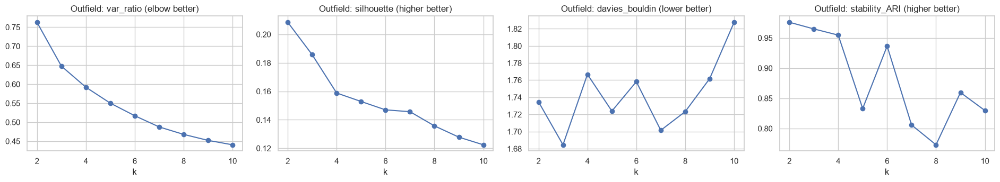

,var_ratio,silhouette,davies_bouldin,calinski_harabasz,stability_ARI
n_clusters,,,,,
2,0.763,0.208,1.735,"5,294.822",0.976
3,0.648,0.186,1.685,"4,640.765",0.965
4,0.592,0.159,1.767,"3,914.685",0.955
5,0.550,0.153,1.724,"3,485.192",0.833
6,0.517,0.147,1.758,"3,184.978",0.937
7,0.488,0.146,1.701,"2,986.538",0.806
8,0.468,0.136,1.723,"2,769.404",0.773
9,0.452,0.128,1.762,"2,581.778",0.860
10,0.440,0.122,1.828,"2,405.456",0.830


Auto-summary: silhouette max at k=2 (0.208); best in 3..8: k=3 (0.186); DB min at k=3; most stable k=2


In [16]:
of_mask = ~is_gk_arr
df_of = df.loc[of_mask].reset_index(drop=True)
OF_FEATURES = OUTFIELD_ATTRS + PHYSICAL + MONEY
X_of = StandardScaler().fit_transform(df_log.loc[of_mask, OF_FEATURES])
Z_of = PCA(3, random_state=RANDOM_STATE).fit_transform(X_of)
n_of = len(X_of)
print(f"Outfield analysis: {n_of:,} players x {len(OF_FEATURES)} features")

km_df, km_models = kmeans_scan(X_of, range(2, 11), "Outfield")
display(km_df)
K_BEST_SIL = int(km_df.silhouette.idxmax())
K_FINAL = int(km_df.loc[3:8, "silhouette"].idxmax())
print(f"Auto-summary: silhouette max at k={K_BEST_SIL} ({km_df.silhouette.max():.3f}); best in 3..8: k={K_FINAL} "
      f"({km_df.loc[K_FINAL, 'silhouette']:.3f}); DB min at k={int(km_df.davies_bouldin.idxmin())}; "
      f"most stable k={int(km_df.stability_ARI.idxmax())}")
labels_km = km_models[K_FINAL].labels_

🔎 **Choosing k for outfield players**
* The silhouette is **low for every k** (0.21 at k = 2, 0.19 at k = 3, decreasing to 0.12 at k = 10) — well below the 0.52 of the GK/outfield split. **The outfield population has no strong cluster structure.**
* The variance ratio decreases smoothly with no clear elbow (0.76 → 0.44).
* Davies–Bouldin is best at k = 3; stability is high for k = 2–4 (ARI > 0.95) and drops for larger k — larger partitions are not reproducible.
* **Methodological choice:** k = 2 is a single cut along the dominant direction, which is not a useful segmentation. We take the best silhouette in the range 3–8 → **k = 3**, which is also the Davies–Bouldin optimum and very stable (ARI = 0.97). The reported k = 2 result is transparent evidence that the "best" k is the trivial one.

### 4.4 Agglomerative clustering (Ward) and the effect of the linkage

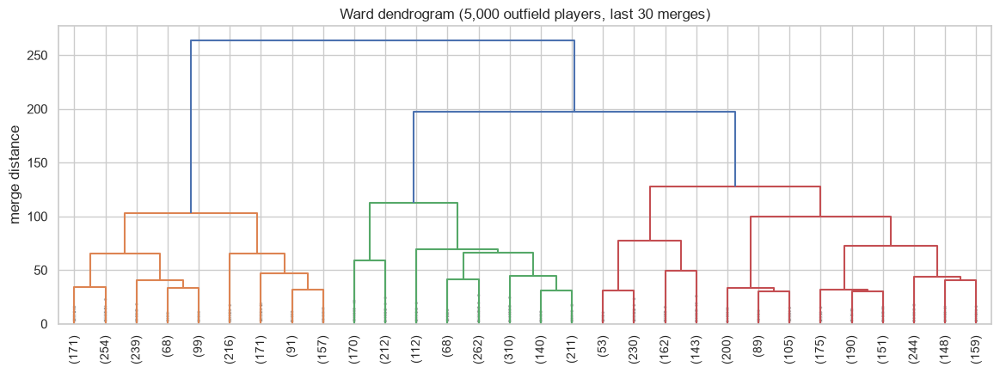

,linkage,largest cluster %,cluster sizes,silhouette
0,ward,40.980,"[2049, 1485, 1466]",0.162
1,complete,51.940,"[2597, 2098, 305]",0.136
2,average,98.960,"[4948, 37, 15]",0.190
3,single,99.940,"[4997, 2, 1]",0.145


In [17]:
agg_idx = rng.choice(n_of, 5000, replace=False); X_agg = X_of[agg_idx]
Z_ward = linkage(X_agg, method="ward")
plt.figure(figsize=(14, 4.5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90, show_contracted=True)
plt.title("Ward dendrogram (5,000 outfield players, last 30 merges)"); plt.ylabel("merge distance"); plt.show()

link_rows = []
for link in ["ward", "complete", "average", "single"]:
    lab = AgglomerativeClustering(n_clusters=K_FINAL, linkage=link).fit_predict(X_agg)
    sizes = np.sort(np.bincount(lab))[::-1]
    link_rows.append({"linkage": link, "largest cluster %": 100 * sizes[0] / len(lab), "cluster sizes": sizes.tolist(),
                      "silhouette": silhouette_score(X_agg, lab)})
display(pd.DataFrame(link_rows))

lab_agg_sample = AgglomerativeClustering(n_clusters=K_FINAL, linkage="ward").fit_predict(X_agg)
labels_agg = KNeighborsClassifier(n_neighbors=1).fit(X_agg, lab_agg_sample).predict(X_of)   # extend to all rows

🔎 **Agglomerative clustering**
* The Ward dendrogram has no single dominant gap: several cutting heights are equally plausible — again a continuum.
* **The linkage changes the answer completely:** *average* and *single* linkage put 99% (and 99.94%) of the players into one cluster and isolate a handful of extreme players (the "chaining" effect: a chain of near neighbours links everything); *Ward* and *complete* linkage give balanced groups (41/30/29% and 52/42/6%). Ward's silhouette (0.16) is close to K-Means. The definition of "cluster" is a modeling choice, not a property of the data.
* By-product: the few points that single/average linkage leave alone are natural **anomaly candidates** — a bridge to Section 5.

### 4.5 DBSCAN — choosing `eps` and `min_samples`
`min_samples` = 2·d = 68 (a common heuristic: larger in higher dimensions to avoid spurious dense spots). `eps` is taken at the **knee** of the sorted distance to the 68-th neighbor (maximum distance between the curve and its chord): to the left of the knee points are in dense regions, to the right they are in sparse regions.

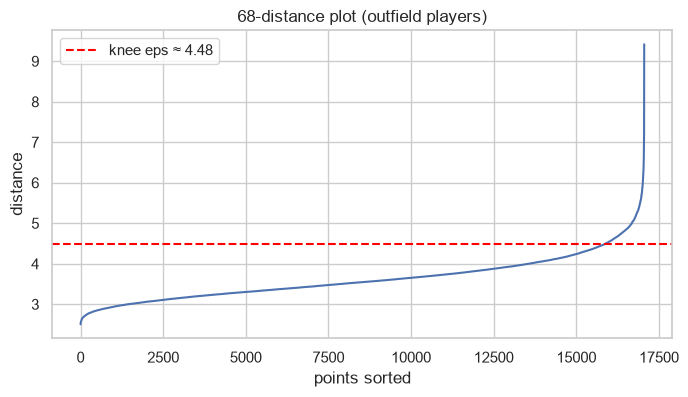

,eps,n_clusters,noise_%,largest_cluster_%
0,2.690,3,88.419,10.373
1,3.140,1,32.233,67.767
2,3.580,1,8.010,91.990
3,4.030,1,1.912,98.088
4,4.480,1,0.422,99.578
5,4.930,1,0.111,99.889
6,5.370,1,0.041,99.959
7,5.820,1,0.012,99.988


Auto-summary (eps=4.48): 1 cluster(s), 0.4% noise
Position groups among DBSCAN noise points: {'ATT': 32, 'DEF': 22, 'MID': 18}


In [18]:
MIN_SAMPLES = 2 * X_of.shape[1]
k_dist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_of).kneighbors(X_of)[0][:, -1])
EPS_KNEE = knee(k_dist)
plt.figure(figsize=(8, 4)); plt.plot(k_dist); plt.axhline(EPS_KNEE, color="red", ls="--", label=f"knee eps ≈ {EPS_KNEE:.2f}")
plt.title(f"{MIN_SAMPLES}-distance plot (outfield players)"); plt.xlabel("points sorted"); plt.ylabel("distance"); plt.legend(); plt.show()

sweep = []
for eps in np.round(np.linspace(EPS_KNEE * .6, EPS_KNEE * 1.3, 8), 2):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_of)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    sweep.append({"eps": eps, "n_clusters": n_cl, "noise_%": 100 * (lab == -1).mean(),
                  "largest_cluster_%": 100 * np.bincount(lab[lab >= 0]).max() / len(lab) if n_cl else 0})
display(pd.DataFrame(sweep))
labels_db = DBSCAN(eps=EPS_KNEE, min_samples=MIN_SAMPLES).fit_predict(X_of)
print(f"Auto-summary (eps={EPS_KNEE:.2f}): {len(set(labels_db)) - (-1 in labels_db)} cluster(s), "
      f"{100*(labels_db==-1).mean():.1f}% noise")
print("Position groups among DBSCAN noise points:", df_of.pos_group[labels_db == -1].value_counts().to_dict())

🔎 **DBSCAN on outfield players**
* Small `eps` (2.7): 88% of players are "noise" and only tiny dense pockets remain. From `eps` ≈ 3.1 upwards there is **exactly one cluster**, which absorbs 68% → 92% → 98% → 99.6% of players as `eps` grows. There is **no value of `eps` that yields two or more large clusters**.
* At the knee (`eps` = 4.48) DBSCAN returns one cluster and 0.4% noise (72 players, mostly attackers and defenders).
* **Interpretation:** there is no low-density gap between defenders, midfielders and attackers in rating space — their profiles blend into each other (wing-backs between defenders and wingers, defensive midfielders between centre-backs and midfielders…). DBSCAN answers a different question than K-Means: it separates the dense **core** of typical players from a thin layer of **unusual** ones — its noise points are natural anomaly candidates.

### 4.6 Gaussian Mixture Model (fourth method, bonus)

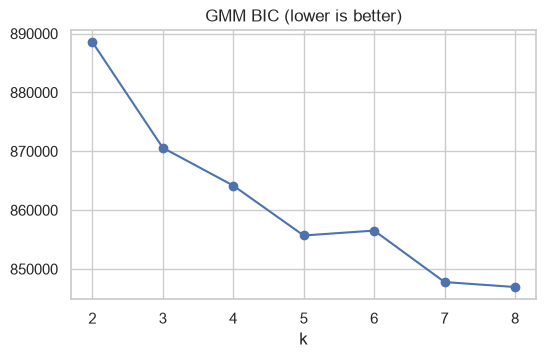

BIC minimal at k=8; share of players with max membership probability < 0.8: 5.9%


In [19]:
bic = {}
for k in range(2, 9):
    bic[k] = GaussianMixture(k, covariance_type="full", random_state=RANDOM_STATE).fit(X_of).bic(X_of)
plt.figure(figsize=(6, 3.5)); plt.plot(list(bic), list(bic.values()), "o-"); plt.title("GMM BIC (lower is better)"); plt.xlabel("k"); plt.show()
gmm = GaussianMixture(K_FINAL, covariance_type="full", n_init=2, random_state=RANDOM_STATE).fit(X_of)
labels_gmm = gmm.predict(X_of); max_proba = gmm.predict_proba(X_of).max(1)
print(f"BIC minimal at k={min(bic, key=bic.get)}; share of players with max membership probability < 0.8: {(max_proba < .8).mean():.1%}")

🔎 The BIC keeps decreasing up to the largest k tested (8): with 17k players and 34 non-Gaussian features, more components always fit the shapes better — another sign that the data are not a mixture of a few Gaussian blobs. With k = 3, 5.9% of players have membership probability < 0.8 — they sit **between** clusters, which is exactly what a continuum looks like.

### 4.7 Comparing the methods (internal metrics, agreement, external validation) and visualization on PCA

,n_clusters,noise_%,var_ratio,silhouette,davies_bouldin,calinski_harabasz,ARI vs position group,NMI vs position group
method,,,,,,,,
K-Means,3,0.000,0.648,0.186,1.685,"4,640.765",0.240,0.261
Agglomerative (Ward),3,0.000,0.691,0.156,1.894,"3,804.132",0.239,0.288
DBSCAN,1,0.422,NaN,NaN,NaN,NaN,0.001,0.001
GMM,3,0.000,0.732,0.114,2.212,"3,120.181",0.352,0.430


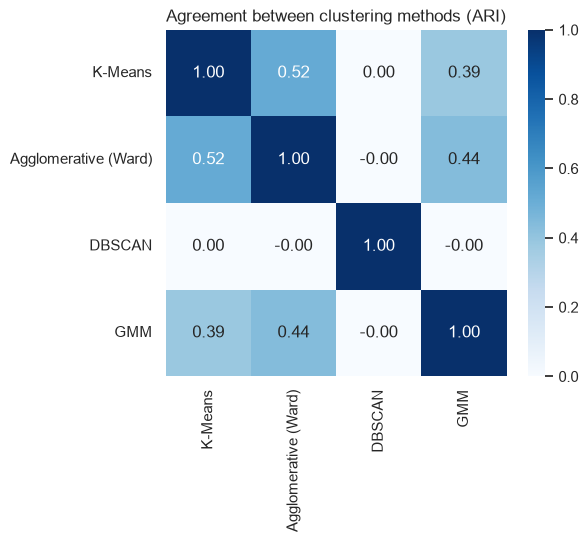

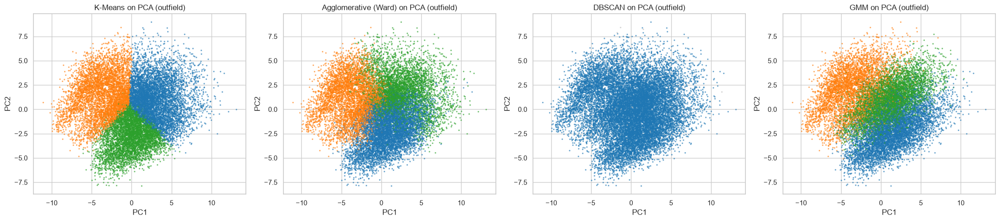

In [20]:
all_labels = {"K-Means": labels_km, "Agglomerative (Ward)": labels_agg, "DBSCAN": labels_db, "GMM": labels_gmm}
summary = pd.DataFrame([evaluate_clustering(X_of, l, n) for n, l in all_labels.items()]).set_index("method")
summary["ARI vs position group"] = [adjusted_rand_score(df_of.pos_group, l) for l in all_labels.values()]
summary["NMI vs position group"] = [normalized_mutual_info_score(df_of.pos_group, l) for l in all_labels.values()]
display(summary)
ari = pd.DataFrame({a: {b: adjusted_rand_score(all_labels[a], all_labels[b]) for b in all_labels} for a in all_labels})
plt.figure(figsize=(5.5, 4.5)); sns.heatmap(ari, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Agreement between clustering methods (ARI)"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
cmap = plt.get_cmap("tab10")
for ax, (name, lab) in zip(axes, all_labels.items()):
    c = [cmap(v % 10) if v >= 0 else (.75, .75, .75, 1) for v in lab]
    ax.scatter(Z_of[:, 0], Z_of[:, 1], c=c, s=2, alpha=.5); ax.set(title=f"{name} on PCA (outfield)", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

#### Cluster profiles — what does each K-Means cluster represent?
Medians in original units (robust to extreme players), the position mix of every cluster, and its best-rated members.

,0,1,2
size_%,36.600,32.100,31.300
attacking_crossing,65.000,45.000,53.000
attacking_finishing,60.000,31.000,59.000
attacking_heading_accuracy,59.000,60.000,50.000
attacking_short_passing,70.000,59.000,60.000
attacking_volleys,56.000,31.000,50.000
skill_dribbling,69.000,51.000,63.000
skill_curve,64.000,37.000,51.000
skill_fk_accuracy,58.000,33.000,43.000
skill_long_passing,66.000,54.000,52.000


Position mix inside each cluster (% of the cluster):


pos_group,ATT,DEF,MID
row_0,,,
0,17.400,25.700,56.900
1,0.300,82.000,17.700
2,48.100,5.100,46.800


Most common detailed positions per cluster and 3 best-rated examples:
  Cluster 0: CM 22%, CDM 14%, ST 12% | e.g. L. Messi, R. Lewandowski, Cristiano Ronaldo
  Cluster 1: CB 55%, CDM 13%, RB 13% | e.g. K. Koulibaly, S. Savić, Felipe
  Cluster 2: ST 35%, RM 12%, LM 12% | e.g. Pepê, G. Caprari, J. Macías


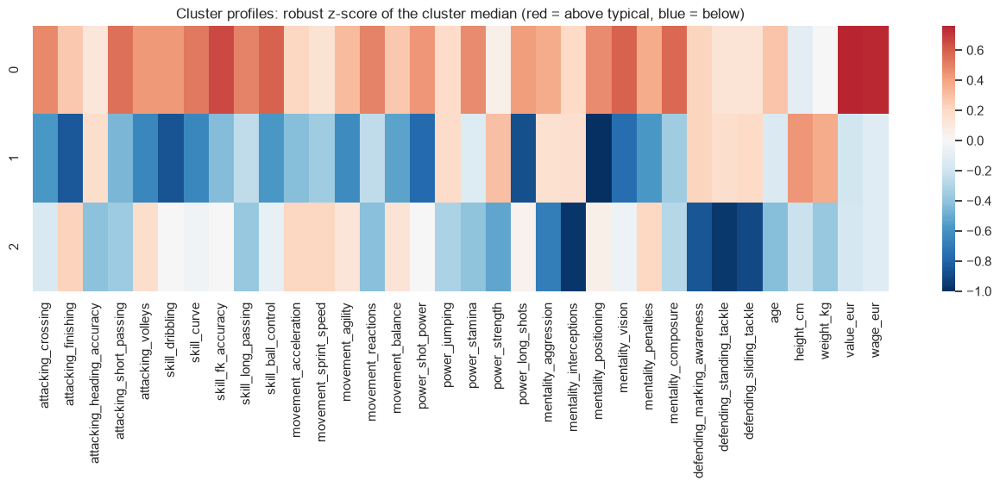

In [21]:
prof = df_of.groupby(labels_km)[OF_FEATURES + ["overall"]].median()
prof.insert(0, "size_%", 100 * pd.Series(labels_km).value_counts(normalize=True).sort_index().values)
display(prof.T.round(1))
print("Position mix inside each cluster (% of the cluster):")
display((100 * pd.crosstab(labels_km, df_of.pos_group, normalize="index")).round(1))
print("Most common detailed positions per cluster and 3 best-rated examples:")
first_pos_of = df_of.player_positions.str.split(",").str[0]
for c in sorted(np.unique(labels_km)):
    m = labels_km == c
    top_pos = first_pos_of[m].value_counts(normalize=True).head(3)
    stars = df_of[m].nlargest(3, "overall").short_name.tolist()
    print(f"  Cluster {c}: {', '.join(f'{p} {v:.0%}' for p, v in top_pos.items())} | e.g. {', '.join(stars)}")

rz = (prof[OF_FEATURES] - df_of[OF_FEATURES].median()) / (df_of[OF_FEATURES].quantile(.75) - df_of[OF_FEATURES].quantile(.25))
plt.figure(figsize=(16, 4)); sns.heatmap(rz, cmap="RdBu_r", center=0, annot=False)
plt.title("Cluster profiles: robust z-score of the cluster median (red = above typical, blue = below)"); plt.show()

🔎 **What the three K-Means clusters represent — and what they do not**

| Cluster | Size | Typical profile (medians) | Who is in it |
|---|---|---|---|
| **"Established all-round players"** | 37% | the highest ratings on almost everything (overall 71), oldest (27), most expensive (€2.2M, €9k/week) | mixed positions (57% MID, 26% DEF, 17% ATT): Messi, Lewandowski, Cristiano Ronaldo… |
| **"Defenders"** | 32% | high tackling/marking/interceptions (≈ 61–64), strong and tall (184 cm), weak finishing (31) | 82% defenders (55% centre-backs): Koulibaly, Savić, Felipe |
| **"Young attacking players"** | 31% | fast (72), weak defending (≈ 30), youngest (22), low value/wage, overall 62 | 48% ATT, 47% MID (strikers, wide midfielders) |

**Critical reading:** only one cluster ("defenders") is a *role*. The other two are separated mainly by **level and age**: the first cluster gathers good players of *any* position, the third gathers young/weaker attacking players. The external validation agrees: ARI with the position groups is only 0.24 for K-Means and Ward (0.35 for GMM). The clusters are meaningful — "established vs. developing players" is a real distinction for scouting — but they are dominated by a **quality factor** that masks roles. The next section tests this explicitly.

### 4.8 Level vs. shape — separating "how good" from "what kind of player"
**Hypothesis (from the profiles above):** the dominant direction among outfield players is *overall quality* — good players are good at almost everything — so K-Means slices players by level rather than by role. If we subtract from each player his own average rating, what remains is his **profile shape** (relative strengths and weaknesses). Mathematically we remove the "size" component $\bar{x}_i\mathbf{1}$ from each vector $x_i$ (row-centering), as is done in compositional and morphometric analyses ("size vs. shape").
We then repeat K-Means on the shape vectors and check (externally) whether clusters now match real positions better.

In [22]:
# "Level" = how good a player is overall (mean of his 29 outfield ratings); "shape" = his ratings relative to his own mean.
ratings = df_of[OUTFIELD_ATTRS].values.astype(float)
level = ratings.mean(1, keepdims=True)
X_shape = StandardScaler().fit_transform(ratings - level)
print(f"Correlation of outfield PC1 with the player's mean rating: {abs(np.corrcoef(Z_of[:, 0], level.ravel())[0, 1]):.2f}; "
      f"with 'overall': {abs(np.corrcoef(Z_of[:, 0], df_of.overall)[0, 1]):.2f}")
rows = []
for k in [3, 4, 5, 6]:
    lab_lvl = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_of)
    lab_shp = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_shape)
    rows.append({"k": k, "ARI vs position — original features": adjusted_rand_score(df_of.pos_group, lab_lvl),
                 "ARI vs position — shape only": adjusted_rand_score(df_of.pos_group, lab_shp),
                 "silhouette — shape only": silhouette_score(X_shape, lab_shp, sample_size=5000, random_state=RANDOM_STATE)})
display(pd.DataFrame(rows).set_index("k"))

K_SHAPE = 4
labels_shape = KMeans(K_SHAPE, n_init=10, random_state=RANDOM_STATE).fit_predict(X_shape)
first_pos_of = df_of.player_positions.str.split(",").str[0]
print(f"Shape-based clusters (k={K_SHAPE}): position mix and examples")
display((100 * pd.crosstab(labels_shape, first_pos_of, normalize="index")).round(0).loc[:, lambda t: t.max() > 8])
for c in range(K_SHAPE):
    m = labels_shape == c
    strongest = (pd.Series(X_shape[m].mean(0), index=OUTFIELD_ATTRS).sort_values(ascending=False).head(4).index
                 .str.split("_", n=1).str[1].tolist())
    print(f"  Cluster {c} ({m.mean():.0%}): relative strengths = {', '.join(strongest)} | e.g. "
          f"{', '.join(df_of[m].nlargest(4, 'overall').short_name)}")

Correlation of outfield PC1 with the player's mean rating: 0.90; with 'overall': 0.72


,ARI vs position — original features,ARI vs position — shape only,silhouette — shape only
k,,,
3,0.240,0.299,0.179
4,0.215,0.315,0.159
5,0.211,0.331,0.146
6,0.190,0.291,0.125


Shape-based clusters (k=4): position mix and examples


player_positions,CAM,CB,CDM,CM,LB,LM,RB,RM,RW,ST
row_0,,,,,,,,,,
0,2.000,0.000,0.000,0.000,0.000,3.000,0.000,3.000,2.000,87.000
1,0.000,86.000,8.000,0.000,2.000,0.000,3.000,0.000,0.000,0.000
2,2.000,5.000,20.000,25.000,19.000,2.000,18.000,3.000,1.000,0.000
3,24.000,0.000,0.000,12.000,0.000,19.000,0.000,18.000,10.000,5.000


  Cluster 0 (16%): relative strengths = finishing, penalties, volleys, positioning | e.g. R. Lewandowski, Cristiano Ronaldo, K. Mbappé, H. Kane
  Cluster 1 (20%): relative strengths = marking_awareness, heading_accuracy, strength, standing_tackle | e.g. Casemiro, V. van Dijk, Sergio Ramos, Marquinhos
  Cluster 2 (40%): relative strengths = interceptions, sliding_tackle, standing_tackle, marking_awareness | e.g. N. Kanté, J. Kimmich, M. Verratti, L. Goretzka
  Cluster 3 (24%): relative strengths = dribbling, curve, vision, fk_accuracy | e.g. L. Messi, Neymar Jr, K. De Bruyne, H. Son


🔎 **Removing "level" reveals "roles"**
* The first principal component of outfield players correlates **0.90** with a player's mean rating: PC1 *is* quality.
* After row-centering, agreement with positions **rises for every k** (ARI 0.30–0.33 vs. 0.19–0.24 with the original features), although silhouettes stay low (0.13–0.18) — the roles are more correct but still not separated by gaps.
* The k = 4 shape clusters are recognisable football roles:
  * **Strikers / finishers** (16%; 87% ST) — relative strengths: finishing, penalties, volleys, positioning — Lewandowski, Cristiano Ronaldo, Mbappé, Kane.
  * **Centre-backs** (20%; 86% CB) — marking, heading, strength, tackling — Casemiro, Van Dijk, Sergio Ramos, Marquinhos.
  * **Ball-winning midfielders and full-backs** (40%; CM/CDM/LB/RB) — interceptions, tackling, but also stamina — Kanté, Kimmich, Verratti, Goretzka.
  * **Creative attackers / wingers** (24%; CAM/LM/RM/RW) — dribbling, curve, vision, free kicks — Messi, Neymar, De Bruyne, Son.
* **Lesson:** "no clusters" depends on the representation. The same data contain a dominant *level* factor and a weaker *role* structure; which one the algorithm finds depends on how we represent the players. Messi lands with Lewandowski in the "level" clustering, and with Neymar and De Bruyne in the "shape" clustering — both statements are true.

### 4.9 Clustering the feature space (transpose of the data matrix)
Now each of the 39 **features** is a point in $\mathbb{R}^{n}$ (its standardized values over all players). For standardized columns,
$$\|x_a-x_b\|^2 = 2n\,(1-r_{ab}),$$
so Euclidean distance between features is a monotone function of their correlation. Clustering features = grouping variables that carry the same information. We use (i) hierarchical clustering (average linkage) with distance $1-|r|$ — sign-insensitive, because a feature and its mirror image carry the same information; (ii) K-Means on $X^\top$ (sign-sensitive) shown on a 2-D MDS map.

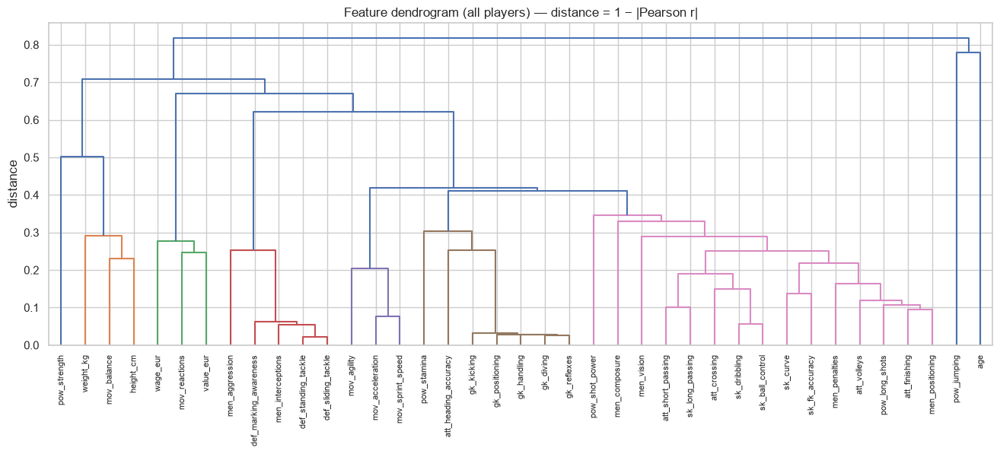

Group 1 (3): movement_balance, height_cm, weight_kg
Group 2 (1): power_strength
Group 3 (3): movement_reactions, value_eur, wage_eur
Group 4 (5): mentality_aggression, mentality_interceptions, defending_marking_awareness, defending_standing_tackle, defending_sliding_tackle
Group 5 (3): movement_acceleration, movement_sprint_speed, movement_agility
Group 6 (7): attacking_heading_accuracy, power_stamina, goalkeeping_diving, goalkeeping_handling, goalkeeping_kicking, goalkeeping_positioning, goalkeeping_reflexes
Group 7 (15): attacking_crossing, attacking_finishing, attacking_short_passing, attacking_volleys, skill_dribbling, skill_curve, skill_fk_accuracy, skill_long_passing, skill_ball_control, power_shot_power, power_long_shots, mentality_positioning, mentality_vision, mentality_penalties, mentality_composure
Group 8 (1): power_jumping
Group 9 (1): age

Most isolated features (distance to nearest other feature):


,distance
age,0.547
power_jumping,0.546
power_strength,0.388
power_stamina,0.253
attacking_heading_accuracy,0.251


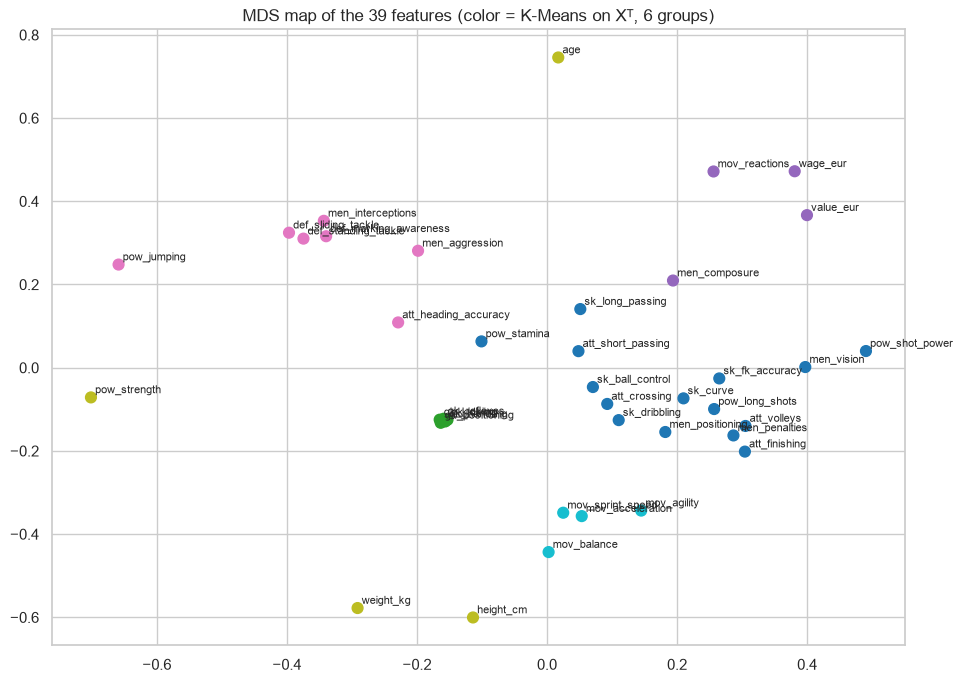

Mean correlation between goalkeeping ratings — all players: Pearson 0.97, Spearman 0.32; goalkeepers only: Pearson 0.84; outfield only: Pearson 0.06
Mean |ρ| between outfield ratings — all players: 0.44, outfield only: 0.37


In [23]:
rho_p = pd.DataFrame(X, columns=FEATURES).corr(method="pearson")
rho_s = pd.DataFrame(X, columns=FEATURES).corr(method="spearman")
dist_feat = 1 - rho_p.abs()
Z_feat = linkage(squareform(dist_feat.values, checks=False), method="average")
short = [f.replace("attacking_", "att_").replace("mentality_", "men_").replace("movement_", "mov_")
          .replace("defending_", "def_").replace("goalkeeping_", "gk_").replace("power_", "pow_").replace("skill_", "sk_") for f in FEATURES]
plt.figure(figsize=(16, 5.5))
dendrogram(Z_feat, labels=short, leaf_rotation=90, color_threshold=0.35)
plt.title("Feature dendrogram (all players) — distance = 1 − |Pearson r|"); plt.ylabel("distance"); plt.show()

FEATURE_CUT = 0.35
feat_groups = pd.Series(fcluster(Z_feat, t=FEATURE_CUT, criterion="distance"), index=FEATURES, name="group")
for g, members in feat_groups.groupby(feat_groups):
    print(f"Group {g} ({len(members)}): {', '.join(members.index)}")
nearest = dist_feat.where(dist_feat > 0).min().sort_values(ascending=False)
print("\nMost isolated features (distance to nearest other feature):"); display(nearest.head(5).to_frame("distance"))

# K-Means on the transposed matrix (Euclidean = sign-sensitive correlation distance) + MDS map
feat_km = pd.Series(KMeans(6, n_init=10, random_state=RANDOM_STATE).fit_predict(X.T), index=FEATURES)
pos = MDS(n_components=2, dissimilarity="precomputed", random_state=RANDOM_STATE).fit_transform(dist_feat.values)
plt.figure(figsize=(11, 8)); plt.scatter(pos[:, 0], pos[:, 1], c=feat_km.values, cmap="tab10", s=60)
for (x_, y_), f in zip(pos, short): plt.annotate(f, (x_, y_), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.title("MDS map of the 39 features (color = K-Means on Xᵀ, 6 groups)"); plt.show()

# Why do Pearson and Spearman disagree so much for the goalkeeping block?
gk_pairs = [(a, b) for i, a in enumerate(GOALKEEPING) for b in GOALKEEPING[i+1:]]
def mean_r(frame, method): return np.mean([frame[a].corr(frame[b], method=method) for a, b in gk_pairs])
print(f"Mean correlation between goalkeeping ratings — all players: Pearson {mean_r(df_raw, 'pearson'):.2f}, "
      f"Spearman {mean_r(df_raw, 'spearman'):.2f}; goalkeepers only: Pearson {mean_r(df_raw[is_gk_arr], 'pearson'):.2f}; "
      f"outfield only: Pearson {mean_r(df_raw[~is_gk_arr], 'pearson'):.2f}")
# Does the feature structure change when goalkeepers are removed?
rho_of = pd.DataFrame(X_of, columns=OF_FEATURES).corr(method="spearman")
print(f"Mean |ρ| between outfield ratings — all players: {rho_s.loc[OUTFIELD_ATTRS, OUTFIELD_ATTRS].abs().values[np.triu_indices(29, 1)].mean():.2f}, "
      f"outfield only: {rho_of.loc[OUTFIELD_ATTRS, OUTFIELD_ATTRS].abs().values[np.triu_indices(29, 1)].mean():.2f}")

🔎 **What feature clustering reveals**
* **Groups of related / redundant features** (cut at 1 − |r| = 0.35):
  1. **Technical / attacking** (15 features): crossing, finishing, passing, volleys, dribbling, curve, free kicks, ball control, shot power, long shots, positioning, vision, penalties, composure.
  2. **Defensive** (5): aggression, interceptions, marking, standing and sliding tackle.
  3. **Goalkeeping** (5), joined by heading accuracy and stamina — because those two are the outfield skills on which goalkeepers are lowest (negative correlation through the GK split).
  4. **Pace** (3): acceleration, sprint speed, agility.
  5. **Body** (3): height, weight and (negatively) balance — tall players have lower balance ratings.
  6. **Status** (3): value, wage and reactions — reactions is the rating most tied to a player's level, hence to his price.
* **Isolated features:** **age** (distance 0.55 to its nearest feature), **jumping** (0.55) and **strength** (0.39). They carry information that no other feature reproduces; dropping them would lose information, whereas dropping 14 of the 15 technical ratings would lose little.
* **Hierarchy:** the dendrogram merges technical with pace and then with defensive skills at higher levels ("outfield skill" in general), and goalkeeping joins last — the feature hierarchy mirrors the sample hierarchy (GK vs. outfield, then roles).
* **Pearson vs. Spearman inside the goalkeeping block:** mean r = 0.97 among all players, 0.84 among goalkeepers only, but **0.06 among outfield players** (Spearman over all players 0.32). The block is held together by the two-population structure, not by a common ability among outfield players — the filler values are noise. (Removing goalkeepers also lowers the mean |ρ| between outfield ratings from 0.44 to 0.37.)
* **Insights not visible when clustering samples:** sample clustering told us *which players* are similar; feature clustering tells us *why* — five or six latent factors (technique, defence, pace, body, status, goalkeeping) organize 39 ratings. It also explains why PCA needs only ~4 effective dimensions, and suggests a compact, interpretable feature set (one representative per group).
* **Where feature clustering is especially useful:** genomics (co-expressed gene modules), finance (sectors of co-moving stocks), sensor networks (redundant sensors), questionnaires (items measuring the same trait), and feature selection before regression (multicollinearity).

### 4.10 Clustering — discussion
* **Why do the algorithms produce different clusters?** Each encodes a different *definition* of a cluster. K-Means/Ward: compact spherical groups (they must return $k$ groups whatever the data); GMM: overlapping ellipsoids with soft membership; DBSCAN: density-connected regions separated by gaps. On the goalkeeper/outfield split (a real gap) **all definitions agree**. Inside the outfield population (a continuum) each definition cuts differently and DBSCAN refuses to cut at all.
* **Sensitivity to hyperparameters:** $k$ (metrics disagree: silhouette prefers 2, BIC keeps decreasing up to 8); the linkage (single/average linkage → one giant cluster + a few outliers; Ward/complete → balanced groups); `eps` (within a factor of ≈1.5 DBSCAN goes from "almost everything is noise" to "everything is one cluster"); the feature representation (raw ratings → clusters by level; row-centered ratings → clusters by role).
* **Cluster geometry:** centroid methods produce Voronoi cells with linear boundaries; GMM produces quadratic boundaries; DBSCAN follows the data's shape. In the PCA plots the K-Means boundaries are straight cuts through one continuous cloud.
* **Density-based vs. centroid-based:** centroid methods are tools for **segmentation** (useful partitions of a continuum: "young attacking players", "defenders", "established all-rounders"); density methods are tools for **discovery** (are there groups separated by empty space?) — and they answer honestly: only goalkeepers are separated.
* **When does clustering fail?** When there is no gap (outfield roles); when one dominant factor (here *quality*, or *goalkeeper vs. not*) masks the structure of interest; when filler values or censoring create artificial structure; when densities differ between groups; and in high dimensions where distances concentrate (Section 7).

# 5. Multi-Dimensional Anomaly Detection (25%)
To compare methods fairly, every method produces a continuous **anomaly score**, and we flag the same budget: the top **1%** of players (192 players overall; 171 in the outfield analysis). Because there are no labels, the budget is a choice, not a fact.

**Plan.** 5.1–5.3 apply the three required methods to *all* players (39 features). 5.4 shows that global methods are dominated by goalkeepers and introduces context-dependent detection. 5.5 re-runs all methods on the homogeneous outfield population, which is the basis for the comparison in Section 6.

In [24]:
CONTAMINATION = 0.01
N_ANOM = int(round(CONTAMINATION * n_samples))
def top_k_flags(score, k=N_ANOM):
    flags_ = np.zeros(len(score), bool); flags_[np.argsort(score)[-k:]] = True; return flags_
def jaccard(a, b): return (a & b).sum() / (a | b).sum()
scores = {}
print(f"Anomaly budget: top {CONTAMINATION:.0%} = {N_ANOM} players per method")

Anomaly budget: top 1% = 192 players per method


## 5.1 Z-score method
📘 For each feature: $z_{ij}=(x_{ij}-\bar x_j)/s_j$; classical rule: anomalous if $|z_{ij}|>3$.
* **Gaussian assumption.** Under normality $P(|Z|>3)=0.27\%$. That number is meaningful only if the feature is Gaussian; for skewed, bounded or multi-modal features the rule over- or under-flags.
* **Feature-wise vs. global.** The rule tests each feature separately. Two ways to combine: (a) **max-rule** — score $=\max_j|z_{ij}|$ (a player is anomalous if he is extreme on *any* feature); (b) **multivariate** — the **Mahalanobis distance** $D_i^2=(x_i-\mu)^\top\Sigma^{-1}(x_i-\mu)$, which accounts for correlations; under multivariate normality $D^2\sim\chi^2_d$. Because the mean and covariance are themselves distorted by outliers (*masking*), we use a **robust** estimate: the Minimum Covariance Determinant (MCD) uses the 75% of points with the most compact covariance.
* **Why it fails in high dimensions.** (1) Multiple testing: with $d$ independent Gaussian features, a perfectly normal row has at least one $|z|>3$ with probability $1-0.9973^d$ (10% for $d=39$). (2) Feature-wise rules miss anomalies that are unusual only in **combination** (e.g. a fast player with poor acceleration). (3) $\Sigma$ needs $n\gg d$ to be estimated reliably and becomes ill-conditioned when features are redundant (condition number ≈ 970 here).

,raw: % |z|>3,log: % |z|>3
goalkeeping_positioning,3.301,3.301
goalkeeping_reflexes,3.123,3.123
goalkeeping_handling,3.113,3.113
goalkeeping_kicking,3.097,3.097
goalkeeping_diving,2.941,2.941
value_eur,1.841,0.855
movement_acceleration,0.819,0.819
movement_sprint_speed,0.694,0.694
attacking_short_passing,0.469,0.469
movement_reactions,0.386,0.386


Gaussian expectation: 0.27% per feature; for 'any of 39' independent features: 10.0%
Players with at least one |z|>3: 1,463; of them goalkeepers: 1,259 (59% of all goalkeepers)

χ²(0.99, df=39) = 62.4. Above threshold: classical 7.6%, robust MCD 23.1% (expected under normality: 1%)
Goalkeepers among MCD 'support' (the 14,743 rows used to estimate the covariance): 0


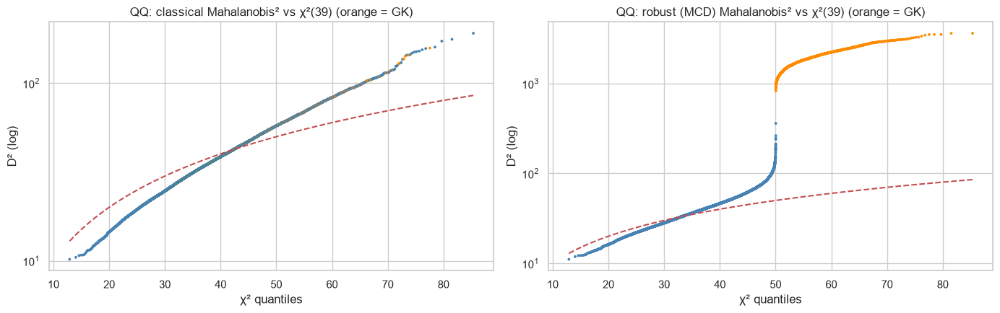

In [25]:
z_raw = np.abs(stats.zscore(df_raw.values)); z_log = np.abs(X)
fw = pd.DataFrame({"raw: % |z|>3": 100 * (z_raw > 3).mean(0), "log: % |z|>3": 100 * (z_log > 3).mean(0)}, index=FEATURES)
fw = fw[(fw > 0).any(axis=1)].sort_values("log: % |z|>3", ascending=False)
fw.loc["ANY feature"] = [100 * (z_raw > 3).any(1).mean(), 100 * (z_log > 3).any(1).mean()]
display(fw)
print(f"Gaussian expectation: 0.27% per feature; for 'any of {n_features}' independent features: {100*(1-0.9973**n_features):.1f}%")
flag_any = (z_log > 3).any(1)
print(f"Players with at least one |z|>3: {flag_any.sum():,}; of them goalkeepers: {(flag_any & is_gk_arr).sum():,} "
      f"({(flag_any & is_gk_arr).sum() / is_gk_arr.sum():.0%} of all goalkeepers)")

md_classic = EmpiricalCovariance().fit(X).mahalanobis(X)
mcd = MinCovDet(random_state=RANDOM_STATE, support_fraction=0.75).fit(X)
md_robust = mcd.mahalanobis(X)
chi2_thr = stats.chi2.ppf(0.99, df=n_features)
print(f"\nχ²(0.99, df={n_features}) = {chi2_thr:.1f}. Above threshold: classical {100*(md_classic > chi2_thr).mean():.1f}%, "
      f"robust MCD {100*(md_robust > chi2_thr).mean():.1f}% (expected under normality: 1%)")
print(f"Goalkeepers among MCD 'support' (the {mcd.support_.sum():,} rows used to estimate the covariance): "
      f"{(mcd.support_ & is_gk_arr).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
q = stats.chi2.ppf((np.arange(1, n_samples + 1) - .5) / n_samples, df=n_features)
for ax, d2, title in zip(axes, [md_classic, md_robust], ["classical", "robust (MCD)"]):
    order = np.argsort(d2)
    ax.scatter(q, d2[order], s=3, c=np.where(is_gk_arr[order], "darkorange", "steelblue"))
    ax.plot(q, q, "r--"); ax.set_yscale("log")
    ax.set(title=f"QQ: {title} Mahalanobis² vs χ²({n_features}) (orange = GK)", xlabel="χ² quantiles", ylabel="D² (log)")
plt.tight_layout(); plt.show()

scores["Z-score (max|z|)"] = z_log.max(1)
scores["Mahalanobis (robust)"] = md_robust

🔎 **Z-score results**
* **The Gaussian assumption fails in a systematic way.** The features with the most |z| > 3 are the five goalkeeping ratings (≈ 3% each, 11× the Gaussian 0.27%): 1,259 goalkeepers — **59% of all goalkeepers** — get at least one |z| > 3. The Z-score is not detecting abnormal players; it is detecting the minority population.
* The log transform matters for money: raw `value_eur` flags 1.8% of players, log-value 0.9%; raw wage 1.9% vs. 0.2% after the log.
* The "any feature" rule flags 7.6% of players — *less* than the 10% expected for 39 independent Gaussian features, because the features are strongly correlated (they do not provide 39 independent chances to exceed 3σ).
* **Mahalanobis (multivariate):** above the χ²₃₉ 99% threshold are 7.6% (classical) and **23.1% (robust MCD)** of players, versus the 1% expected under normality. The QQ plots show the goalkeepers (orange) as a separate branch far above the χ² line.
* **Why the robust version flags so much more:** MCD estimates the mean and covariance from the most compact 75% of the data — the **14,743 players in its support contain zero goalkeepers**. Robust statistics are designed to ignore a minority, so the whole goalkeeper population (plus many outfield players) is declared anomalous. "Robust to outliers" becomes "blind to sub-populations".

## 5.2 Isolation Forest
📘 **Isolation mechanism.** Instead of modeling "normal", isolate each point. Each tree is grown on a random subsample (256 rows): pick a **random feature** and a **random split value** between its min and max, recurse until every point is alone. **Anomalies are few and different**, so they are separated after few cuts — a **short path length** $h(x)$.
**Role of randomness.** One random tree is a noisy measurement; averaging over 300 trees gives a stable expected path length. Subsampling also reduces *swamping* (normal points near anomalies) and *masking* (groups of anomalies hiding each other).
**Score.** $s(x,n)=2^{-\mathbb{E}[h(x)]/c(n)}$, with $c(n)=2H(n-1)-2(n-1)/n$ the average path length of an unsuccessful search in a binary search tree. $s\to1$: isolated very quickly → anomaly; $s\approx0.5$: average; $s<0.5$: deep inside the data → normal. (scikit-learn returns $-s$; we flip the sign.)
**Contamination.** It does **not** change the trees or scores — only the threshold (`offset_`) that turns scores into labels, i.e. our *prior belief* about the share of anomalies.
**Advantages:** linear time, no distances, insensitive to feature scaling (only the order of values matters for where splits fall), handles heavy tails. **Limitations:** axis-parallel cuts struggle with anomalies that are unusual only in a *combination* of correlated features; with many irrelevant features most cuts are wasted; a large compact group (like goalkeepers) can be isolated by a single cut on the right feature, so it looks "anomalous"; mostly detects **global** anomalies.

,contamination,flagged,score threshold,% GK among flagged
0,0.005,96,0.592,80.208
1,0.010,192,0.586,84.896
2,0.020,384,0.578,89.062
3,0.050,959,0.564,91.554
4,0.100,1918,0.545,90.302


contamination='auto' (threshold s=0.5) flags 3,313 players
Top-1% stability across seeds (mean Jaccard): 0.56


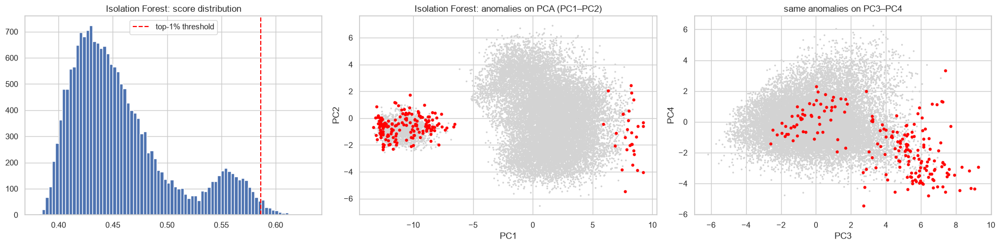

--- Isolation Forest: 192 flagged players ---
Position groups: {'GK': 163, 'ATT': 17, 'MID': 11, 'DEF': 1} | overall rating median: 76 vs 66
Largest mean |z| among flagged: goalkeeping_handling (2.7), goalkeeping_positioning (2.7), goalkeeping_reflexes (2.7), goalkeeping_kicking (2.6), goalkeeping_diving (2.6)


,short_name,age,player_positions,club_name,overall,value_eur,wage_eur,score
0,L. Messi,34,"RW, ST, CF",Paris Saint-Germain,93,"78,000,000.000","320,000.000",0.630
7,M. Neuer,35,GK,FC Bayern München,90,"13,500,000.000","86,000.000",0.629
2,Cristiano Ronaldo,36,"ST, LW",Manchester United,91,"45,000,000.000","270,000.000",0.621
18,Ederson,27,GK,Manchester City,89,"94,000,000.000","200,000.000",0.621
23,L. Suárez,34,ST,Atlético de Madrid,88,"44,500,000.000","135,000.000",0.619
8,M. ter Stegen,29,GK,FC Barcelona,90,"99,000,000.000","250,000.000",0.618
83,A. Griezmann,30,"ST, LW, RW",Atlético de Madrid,85,"53,000,000.000","220,000.000",0.610
20,Alisson,28,GK,Liverpool,89,"82,000,000.000","190,000.000",0.610


In [26]:
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1).fit(X)
iso_score = -iso.score_samples(X)
scores["Isolation Forest"] = iso_score
cont_rows = []
for c in [0.005, 0.01, 0.02, 0.05, 0.1]:
    m = IsolationForest(n_estimators=300, contamination=c, random_state=RANDOM_STATE, n_jobs=-1).fit(X)
    pred = m.predict(X) == -1
    cont_rows.append({"contamination": c, "flagged": int(pred.sum()), "score threshold": -m.offset_, "% GK among flagged": 100 * is_gk_arr[pred].mean()})
display(pd.DataFrame(cont_rows))
print(f"contamination='auto' (threshold s=0.5) flags {(iso.predict(X) == -1).sum():,} players")
seed_sets = [top_k_flags(-IsolationForest(n_estimators=300, random_state=s, n_jobs=-1).fit(X).score_samples(X)) for s in range(3)]
print(f"Top-1% stability across seeds (mean Jaccard): {np.mean([jaccard(seed_sets[i], seed_sets[j]) for i in range(3) for j in range(i+1, 3)]):.2f}")

def plot_anomalies(flag, name, color="red"):
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
    ax[0].hist(scores[name], bins=80); ax[0].axvline(np.sort(scores[name])[-N_ANOM], color=color, ls="--", label="top-1% threshold")
    ax[0].set_title(f"{name}: score distribution"); ax[0].legend()
    ax[1].scatter(Z[~flag, 0], Z[~flag, 1], s=2, c="lightgray"); ax[1].scatter(Z[flag, 0], Z[flag, 1], s=10, c=color)
    ax[1].set(title=f"{name}: anomalies on PCA (PC1–PC2)", xlabel="PC1", ylabel="PC2")
    ax[2].scatter(Z[~flag, 2], Z[~flag, 3], s=2, c="lightgray"); ax[2].scatter(Z[flag, 2], Z[flag, 3], s=10, c=color)
    ax[2].set(title="same anomalies on PC3–PC4", xlabel="PC3", ylabel="PC4")
    plt.tight_layout(); plt.show()

def describe_anomalies(flag, name):
    print(f"--- {name}: {flag.sum()} flagged players ---")
    print("Position groups:", df.pos_group[flag].value_counts().to_dict(), "| overall rating median:",
          int(df.overall[flag].median()), "vs", int(df.overall[~flag].median()))
    driver = pd.Series(np.abs(X[flag]).mean(0), index=FEATURES).sort_values(ascending=False)
    print("Largest mean |z| among flagged:", ", ".join(f"{f} ({v:.1f})" for f, v in driver.head(5).items()))
    top = np.argsort(scores[name])[-8:][::-1]
    display(df.loc[top, ["short_name", "age", "player_positions", "club_name", "overall", "value_eur", "wage_eur"]]
              .assign(score=scores[name][top]))

f_iso = top_k_flags(iso_score); plot_anomalies(f_iso, "Isolation Forest"); describe_anomalies(f_iso, "Isolation Forest")

🔎 **Isolation Forest results (all players)**
* **85% of the top 1% are goalkeepers** (163 of 192); with contamination between 0.5% and 10%, goalkeepers are always 80–92% of the flagged players. One random split on any goalkeeping rating isolates the whole goalkeeper group, so goalkeepers have short paths.
* The non-goalkeepers it flags are **superstars**: Messi, Cristiano Ronaldo, Suárez, Griezmann (median overall of flagged players 76 vs. 66). Isolation Forest finds *global* extremes — players at the edge of the cloud in several features at once.
* `contamination='auto'` (threshold s = 0.5) flags 3,313 players (17%): the "automatic" threshold is not a principled anomaly rate. The score distribution has no gap: the top-1% cut is a decision.
* Stability: the top-1% overlap between seeds is only 0.56 — many goalkeepers have nearly identical scores at the threshold, so which of them land in the top 1% is partly random.
* The PC3–PC4 panel shows that several flagged players are unremarkable in PC1–PC2 — the anomaly lies in other directions.

## 5.3 Local Outlier Factor (LOF)
📘 **Local density estimation.** For a point $p$ with $k$ nearest neighbours $N_k(p)$, the *reachability distance* $\text{reach}_k(p,o)=\max\{d_k(o),d(p,o)\}$ smooths distances inside dense neighbourhoods; the **local reachability density** is $\text{lrd}_k(p)=\big(\tfrac1k\sum_{o\in N_k(p)}\text{reach}_k(p,o)\big)^{-1}$ and
$$\text{LOF}_k(p)=\frac1k\sum_{o\in N_k(p)}\frac{\text{lrd}_k(o)}{\text{lrd}_k(p)} .$$
LOF ≈ 1: as dense as its neighbours (normal); LOF ≫ 1: much sparser than its own neighbourhood (**local** outlier).
* **Neighbourhood effects:** the score is *relative*. A player in a sparse region is normal if his neighbours are equally sparse; a player just outside a dense group is anomalous even if he is "central" globally. A dense group (goalkeepers) is normal for LOF, however different it is from everyone else.
* **Sensitivity to $k$:** small $k$ = very local, noisy, sensitive to near-duplicates; large $k$ approaches a global density estimate; groups of anomalies smaller than $k$ can mask each other.
* **Global vs local anomalies:** a *global* anomaly is far from all data (Messi's ratings); a *local* anomaly is unusual relative to its own context (a full-back whose profile differs from the full-backs it most resembles).

,k,Jaccard with k=20,Spearman with k=20,% GK in top 1%
0,5,0.524,0.874,15.625
1,10,0.677,0.964,13.542
2,20,1.000,1.000,13.021
3,50,0.699,0.970,11.979
4,100,0.567,0.933,11.458
5,200,0.428,0.874,10.938


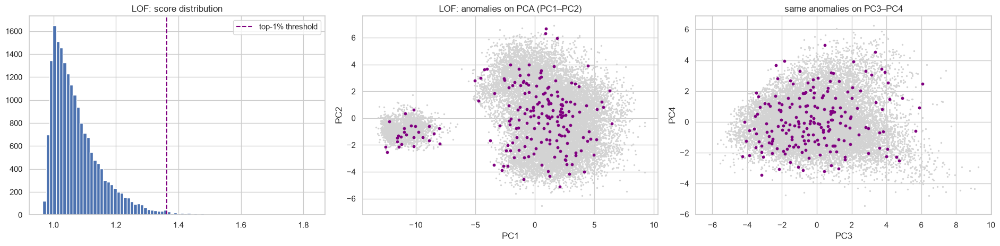

--- LOF: 192 flagged players ---
Position groups: {'MID': 67, 'DEF': 64, 'ATT': 36, 'GK': 25} | overall rating median: 65 vs 66
Largest mean |z| among flagged: power_jumping (1.2), power_strength (1.1), age (1.1), value_eur (1.1), power_stamina (1.1)


,short_name,age,player_positions,club_name,overall,value_eur,wage_eur,score
5041,Jaimosa Cavaco,21,RB,Juventude,70,"1,700,000.000","9,000.000",1.826
1960,S. Viera,38,GK,Junior FC,74,"475,000.000","2,000.000",1.793
4971,V. Milinković-Savić,24,GK,Torino F.C.,70,"1,900,000.000","13,000.000",1.681
17520,E. Munjoma,22,RB,FC Dallas,56,"300,000.000","1,000.000",1.665
5451,L. Licht,40,"LB, LWB, LM",Gimnasia y Esgrima La Plata,69,"9,000.000","5,000.000",1.665
16148,K. Miura,54,ST,Yokohama FC,59,"9,000.000",700.000,1.654
17702,C. Rodas,19,GK,Pachuca,56,"300,000.000",850.000,1.646
5441,Rubén Castro,40,ST,FC Cartagena,69,"9,000.000","3,000.000",1.645


In [27]:
lof_by_k = {k: -LocalOutlierFactor(n_neighbors=k, n_jobs=-1).fit(X).negative_outlier_factor_ for k in [5, 10, 20, 50, 100, 200]}
K_LOF = 20
scores["LOF"] = lof_by_k[K_LOF]
base = top_k_flags(lof_by_k[K_LOF])
display(pd.DataFrame({"k": list(lof_by_k),
                      "Jaccard with k=20": [jaccard(top_k_flags(s), base) for s in lof_by_k.values()],
                      "Spearman with k=20": [stats.spearmanr(s, lof_by_k[K_LOF])[0] for s in lof_by_k.values()],
                      "% GK in top 1%": [100 * is_gk_arr[top_k_flags(s)].mean() for s in lof_by_k.values()]}))
f_lof = top_k_flags(scores["LOF"]); plot_anomalies(f_lof, "LOF", "purple"); describe_anomalies(f_lof, "LOF")

🔎 **LOF results (all players)**
* **LOF is not fooled by the goalkeepers:** only 13% of its top 1% are goalkeepers — about their share in the data (11%). Goalkeepers form a *dense* group, and LOF compares each player with his own neighbourhood.
* LOF flags players who are **isolated within their own neighbourhood**: Jaimosa Cavaco (a right-back with an unusual profile), S. Viera (38-year-old goalkeeper), veterans with imputed values (Licht, Miura, Rubén Castro). Their median overall rating (65) equals the population's — LOF anomalies are **not** stars; they are atypical players of ordinary level.
* **Strong sensitivity to k:** the top-1% overlap with k = 20 is only 0.52 for k = 5 and 0.43 for k = 200, although the full score rankings correlate highly (Spearman 0.87–0.97). The *ranking* is stable; the *identity of the most extreme 1%* is not. We use k = 20 as a compromise between noisy (k = 5) and almost-global (k = 200).

## 5.4 The goalkeeper effect and context-dependent anomalies
What fraction of each method's top 1% are goalkeepers? And what happens if we define "abnormal" **relative to a player's own position group** (a separate Isolation Forest for GK, DEF, MID, ATT, each with the relevant features)?

In [28]:
# (a) How strongly is each global method driven by the goalkeeper sub-population?
gk_share = pd.Series({m: 100 * is_gk_arr[top_k_flags(scores[m])].mean() for m in scores}, name="% goalkeepers in top 1%")
display(gk_share.to_frame().assign(**{"% goalkeepers in data": 100 * is_gk_arr.mean()}))

# (b) Context-dependent anomalies: Isolation Forest fitted separately inside each position group
ctx_score = np.zeros(n_samples)
for grp in ["GK", "DEF", "MID", "ATT"]:
    m = (df.pos_group == grp).values
    feats = (GOALKEEPING if grp == "GK" else OUTFIELD_ATTRS) + PHYSICAL + MONEY
    Xg = StandardScaler().fit_transform(df_log.loc[m, feats])
    ctx_score[m] = -IsolationForest(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(Xg).score_samples(Xg)
f_ctx = top_k_flags(ctx_score)
print(f"Jaccard(global IF, within-position IF) = {jaccard(f_ctx, f_iso):.2f};  position groups flagged within-position: "
      f"{df.pos_group[f_ctx].value_counts().to_dict()}")
print("Flagged ONLY by the within-position model (ordinary globally, unusual for their position):")
only_ctx = np.where(f_ctx & ~f_iso)[0]
display(df.loc[only_ctx[np.argsort(ctx_score[only_ctx])[::-1][:8]], ["short_name", "age", "player_positions", "pos_group", "club_name", "overall"]])

,% goalkeepers in top 1%,% goalkeepers in data
Z-score (max|z|),79.167,11.075
Mahalanobis (robust),100.000,11.075
Isolation Forest,84.896,11.075
LOF,13.021,11.075


Jaccard(global IF, within-position IF) = 0.19;  position groups flagged within-position: {'ATT': 51, 'MID': 49, 'DEF': 47, 'GK': 45}
Flagged ONLY by the within-position model (ordinary globally, unusual for their position):


,short_name,age,player_positions,pos_group,club_name,overall
134,M. Acuña,29,"LB, LM",DEF,Sevilla FC,84
98,Jesús Navas,35,"RB, RM",DEF,Sevilla FC,84
22,Sergio Ramos,35,CB,DEF,Paris Saint-Germain,88
62,João Cancelo,27,"RB, LB",DEF,Manchester City,86
18838,J. Singh,20,"CDM, CB",MID,Jamshedpur FC,51
107,D. Alaba,29,"CB, LB",DEF,Real Madrid CF,84
77,P. Gulácsi,31,GK,GK,RB Leipzig,85
50,Jordi Alba,32,"LB, LM",DEF,FC Barcelona,86


🔎 **The goalkeeper effect and context**
* Goalkeepers are 11% of the data but **79% (Z-score), 100% (robust Mahalanobis), 85% (Isolation Forest)** of the global top 1% — only LOF (13%) is close to their population share. Three of four methods confuse **"belongs to a minority group"** with **"is abnormal"**.
* With a separate Isolation Forest **inside each position group**, the flags are spread evenly (ATT 51, MID 49, DEF 47, GK 45) and overlap with the global model is low (Jaccard 0.19). The new, context-dependent anomalies are players who are ordinary in the global population but unusual *for their position*: **attacking full-backs** (Acuña, Jesús Navas, João Cancelo, Jordi Alba), **ball-playing centre-backs** (Sergio Ramos, Alaba), and a highly-rated goalkeeper (Gulácsi). These are exactly the players football analysts call "atypical" for their role.
* **Lesson:** an anomaly is always "anomalous *relative to something*". Choosing the reference population is part of defining the problem.

## 5.5 Re-analysis on the homogeneous outfield population
Since goalkeepers are a *known sub-population* (not anomalies), the more meaningful question is: **which outfield players are unusual compared with other outfield players?** We re-run the four detectors on the 17,054 outfield players (34 features, same preprocessing). Sections 6 and 7 use these results.

Outfield players: 17,054; anomaly budget 1% = 171


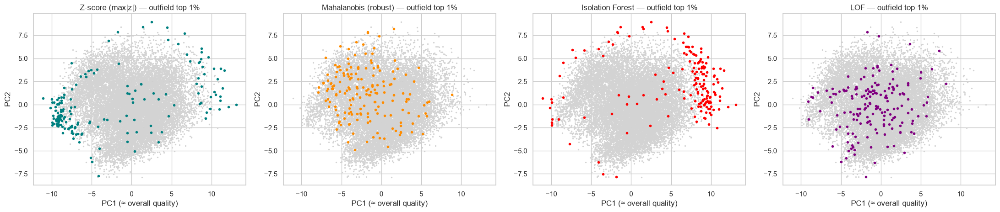

Z-score (max|z|)       median overall 56 | median age 23 | positions {'DEF': 107, 'MID': 34, 'ATT': 30} | top: K. Miura, A. Akinfenwa, O. Oularé, J. Filipovic, K. Mbappé
Mahalanobis (robust)   median overall 66 | median age 29 | positions {'DEF': 105, 'MID': 36, 'ATT': 30} | top: J. Sand, David Mateos, K. Miura, M. Rodríguez, E. Munjoma
Isolation Forest       median overall 84 | median age 29 | positions {'ATT': 73, 'MID': 60, 'DEF': 38} | top: Cristiano Ronaldo, L. Messi, Z. Ibrahimović, H. Kane, R. Lewandowski
LOF                    median overall 65 | median age 27 | positions {'DEF': 72, 'MID': 65, 'ATT': 34} | top: Jaimosa Cavaco, E. Munjoma, L. Licht, Kauã Zanson, K. Miura


In [29]:
# ---- Re-run the four detectors on the homogeneous outfield population (34 features) ----
XA, dfA = X_of, df_of
nA = len(XA); N_A = int(round(CONTAMINATION * nA))
pcaA = PCA(random_state=RANDOM_STATE).fit(XA); ZA = pcaA.transform(XA)
XA_raw = df_raw.loc[of_mask, OF_FEATURES].values
XA_raw_std = StandardScaler().fit_transform(XA_raw)
def flagsA(score, k=None): return top_k_flags(score, N_A if k is None else k)

scoresA = {"Z-score (max|z|)": np.abs(XA).max(1),
           "Mahalanobis (robust)": MinCovDet(random_state=RANDOM_STATE, support_fraction=.75).fit(XA).mahalanobis(XA),
           "Isolation Forest": -IsolationForest(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(XA).score_samples(XA),
           "LOF": -LocalOutlierFactor(n_neighbors=K_LOF, n_jobs=-1).fit(XA).negative_outlier_factor_}
MAIN_METHODS = list(scoresA)
flags = {m: flagsA(scoresA[m]) for m in MAIN_METHODS}
print(f"Outfield players: {nA:,}; anomaly budget 1% = {N_A}")
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, (m, col) in zip(axes, zip(MAIN_METHODS, ["teal", "darkorange", "red", "purple"])):
    f = flags[m]
    ax.scatter(ZA[~f, 0], ZA[~f, 1], s=2, c="lightgray"); ax.scatter(ZA[f, 0], ZA[f, 1], s=9, c=col)
    ax.set(title=f"{m} — outfield top 1%", xlabel="PC1 (≈ overall quality)", ylabel="PC2")
plt.tight_layout(); plt.show()
for m in MAIN_METHODS:
    f = flags[m]
    print(f"{m:22s} median overall {dfA.overall[f].median():.0f} | median age {dfA.age[f].median():.0f} | "
          f"positions {dfA.pos_group[f].value_counts().to_dict()} | top: {', '.join(dfA.short_name[np.argsort(scoresA[m])[::-1][:5]])}")

🔎 **Four methods, four different kinds of anomaly (outfield players)**

| Method | Who is flagged | Median overall / age | Typical examples | Kind of anomaly |
|---|---|---|---|---|
| **Z-score (max)** | mostly **weak defenders** (107 of 171) and extreme individuals | 56 / 23 | Miura, Akinfenwa, Oularé, Mbappé | extreme on **one** feature — often the long *left* tail of technical skills (a centre-back with ball control 27) |
| **Robust Mahalanobis** | defenders and veterans | 66 / 29 | Sand, Miura, M. Rodríguez | **broken correlations** — a combination of ratings that does not fit the usual pattern |
| **Isolation Forest** | **superstars** (ATT 73, MID 60) | **84** / 29 | Cristiano Ronaldo, Messi, Ibrahimović, Kane, Lewandowski | **global** extremes on many features simultaneously |
| **LOF** | ordinary-level players across all positions | 65 / 27 | Jaimosa Cavaco, Munjoma, Licht, Miura | **local** isolation — unusual compared with their nearest neighbours |

The PCA panels show the same story geometrically: Isolation Forest's anomalies sit on the high-quality edge of the cloud (right), Z-score's on the low-technique edge (left), while Mahalanobis and especially LOF anomalies are scattered *inside* the cloud — invisible as extremes in two dimensions.

# 6. Comparison of the Anomaly Detection Methods
## 6.1 Agreement — which anomalies are found by several methods, and which are method-specific?

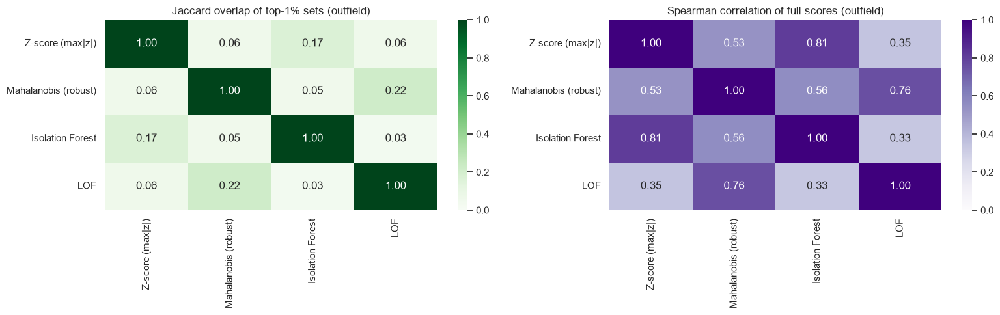

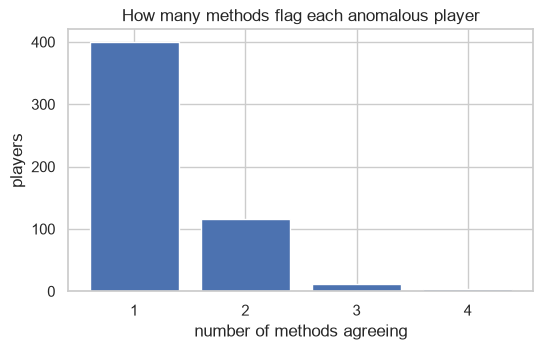

Players flagged by exactly m methods: {1: 400, 2: 116, 3: 12, 4: 4}
Flagged ONLY by one method: {'Z-score (max|z|)': 103, 'Mahalanobis (robust)': 91, 'Isolation Forest': 106, 'LOF': 100}


In [30]:
jac = pd.DataFrame({a: {b: jaccard(flags[a], flags[b]) for b in MAIN_METHODS} for a in MAIN_METHODS})
spear = pd.DataFrame({a: {b: stats.spearmanr(scoresA[a], scoresA[b])[0] for b in MAIN_METHODS} for a in MAIN_METHODS})
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(jac, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=axes[0]); axes[0].set_title("Jaccard overlap of top-1% sets (outfield)")
sns.heatmap(spear, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=axes[1]); axes[1].set_title("Spearman correlation of full scores (outfield)")
plt.tight_layout(); plt.show()
flag_df = pd.DataFrame(flags); votes = flag_df.sum(1)
vc = votes[votes > 0].value_counts().sort_index()
plt.figure(figsize=(6, 3.4)); plt.bar(vc.index.astype(str), vc.values); plt.xlabel("number of methods agreeing"); plt.ylabel("players")
plt.title("How many methods flag each anomalous player"); plt.show()
print("Players flagged by exactly m methods:", vc.to_dict())
print("Flagged ONLY by one method:", {m: int((flag_df[m] & (votes == 1)).sum()) for m in MAIN_METHODS})

In [31]:
def explain_row(i, top=3):
    """Plain-language reason: the most extreme standardized features of outfield player i."""
    z = pd.Series(XA[i], index=OF_FEATURES)
    return "; ".join(f"{f} {'high' if z[f] > 0 else 'low'} (z={z[f]:+.1f}, value={dfA.iloc[i][f]:,.0f})"
                     for f in z.abs().sort_values(ascending=False).head(top).index)

cons = flag_df.index[votes >= 3]
print(f"Flagged by ≥3 of the 4 methods: {len(cons)} players")
t = dfA.loc[cons, ["short_name", "age", "player_positions", "club_name", "overall"]].copy()
t["votes"] = votes[cons]; t["IF score"] = scoresA["Isolation Forest"][cons]
t = t.sort_values(["votes", "IF score"], ascending=False).head(12); t["why"] = [explain_row(i) for i in t.index]; display(t)
for m in MAIN_METHODS:
    only = flag_df.index[flag_df[m] & (votes == 1)]
    for i in only[np.argsort(scoresA[m][only])[::-1][:2]]:
        print(f"Only {m}: {dfA.short_name[i]} ({dfA.player_positions[i]}, {dfA.club_name[i]}, overall {dfA.overall[i]}) -> {explain_row(i)}")

Flagged by ≥3 of the 4 methods: 16 players


,short_name,age,player_positions,club_name,overall,votes,IF score,why
209,N. Süle,25,"CB, RB",FC Bayern München,82,4,0.609,"weight_kg high (z=+3.7, value=99); value_eur h..."
11056,S. Nakamura,43,"CAM, CF, RW",Yokohama FC,63,4,0.597,"value_eur low (z=-4.0, value=9,000); age high ..."
1301,A. D'Alessandro,40,"CAM, RM",Club Nacional de Football,75,4,0.594,"value_eur low (z=-4.0, value=9,000); power_sta..."
14547,K. Miura,54,ST,Yokohama FC,59,4,0.573,"age high (z=+6.3, value=54); value_eur low (z=..."
21,E. Haaland,20,ST,Borussia Dortmund,88,3,0.617,"value_eur high (z=+4.0, value=137,500,000); mo..."
16591,M. McChrystal,37,CB,Derry City,52,3,0.581,"value_eur low (z=-3.6, value=15,000); power_st..."
137,S. Coates,30,CB,Sporting CP,83,3,0.578,"movement_balance low (z=-3.0, value=31); attac..."
17022,J. Bradley-Walsh,20,CB,Finn Harps,48,3,0.572,"skill_ball_control low (z=-3.8, value=27); att..."
1306,J. Sand,40,ST,Club Atlético Lanús,75,3,0.565,"value_eur low (z=-4.0, value=9,000); age high ..."
14816,S. Ono,41,"CAM, CM",Hokkaido Consadole Sapporo,58,3,0.541,"value_eur low (z=-4.0, value=9,000); power_sta..."


Only Z-score (max|z|): O. Oularé (ST, Barnsley, overall 68) -> weight_kg high (z=+4.5, value=104); movement_balance low (z=-2.8, value=33); power_stamina low (z=-2.6, value=38)
Only Z-score (max|z|): J. Filipovic (RB, Mjällby AIF, overall 56) -> attacking_short_passing low (z=-4.3, value=23); skill_ball_control low (z=-3.5, value=30); skill_long_passing low (z=-3.0, value=21)
Only Mahalanobis (robust): Rafael Santos (CB, APOEL Nicosia FC, overall 66) -> skill_dribbling low (z=-3.4, value=21); skill_long_passing low (z=-2.8, value=23); mentality_vision low (z=-2.4, value=25)
Only Mahalanobis (robust): A. Alcáraz (CB, Club Olimpia, overall 71) -> movement_sprint_speed low (z=-3.3, value=31); skill_long_passing low (z=-3.0, value=20); age high (z=+2.8, value=38)
Only Isolation Forest: Z. Ibrahimović (ST, AC Milan, overall 84) -> weight_kg high (z=+3.1, value=95); age high (z=+3.0, value=39); mentality_composure high (z=+2.9, value=90)
Only Isolation Forest: L. Suárez (ST, Atlético de Madr

🔎 **Agreement between methods**
* **Agreement is low.** Jaccard overlap of the top-1% sets: Z–IF 0.16, Mahalanobis–LOF 0.22, all other pairs 0.03–0.06. Only **4 players are flagged by all four methods** and 16 by at least three; 402 of the 533 flagged players are flagged by **one method only**.
* **The full score rankings agree much more** than the top-1% sets: Spearman Z–IF 0.81, Mahalanobis–LOF 0.76. There are two "families": **global-extreme detectors** (Z-score, Isolation Forest) and **structure/density detectors** (Mahalanobis, LOF). Methods broadly agree on who is unusual, but the exact top 1% is fragile because the threshold cuts through a dense continuum of scores.
* **Consensus anomalies (most trustworthy):**
  * **Niklas Süle** — weight 99 kg with balance 32 *and* a value of €40.5M: a heavy, slow-turning but elite centre-back — a real and rare profile.
  * **Kazuyoshi Miura (54), Shunsuke Nakamura (43), Andrés D'Alessandro (40)** — the oldest players: very high age, very low pace and stamina…
  * …but also **value = €9,000**, the value *we imputed*. Six of the twelve players in the consensus table are veterans with imputed value: **part of their "anomaly" was created by our preprocessing**. They are real anomalies (age), amplified by an artifact.
  * **Erling Haaland** (20 years old, €137.5M, 94 kg, reactions 88) — a genuinely exceptional young player.
  * **Adebayo Akinfenwa** (110 kg) — legitimately extreme.
* **Method-specific anomalies and why:** Z-score alone flags single extreme values (Oularé's 104 kg; Filipovic's very low passing); Mahalanobis alone flags *inconsistent profiles* (a centre-back with very low dribbling and vision relative to his level); Isolation Forest alone flags stars whose extremes are spread over several features (Ibrahimović, Suárez); LOF alone flags players in sparse local neighbourhoods (Kauã Zanson; Delli Carri with very low vision/positioning for his neighbourhood).

**Which results are more meaningful here?** For *data-quality* purposes, the consensus set and robust Mahalanobis (inconsistent rating combinations are what a rating error would produce). For *scouting* purposes, Isolation Forest (exceptional players) and the within-position model (atypical role profiles). There is no single "correct" detector — the right one depends on the question.

## 6.2 Sensitivity to feature scaling
Each method is re-run on (A) raw, unscaled features; (B) standardized features without the log of money; and compared with (C) our pipeline (log + standardize). Value = Jaccard overlap of the top-1% sets with (C).

In [32]:
def run_all_methods(data, seed=RANDOM_STATE, mcd_sample=5000):
    """Anomaly scores (higher = more anomalous) of the four methods on `data`.
    For speed, the robust covariance (MCD) is estimated on a random subsample and applied to all rows."""
    out = {"Z-score (max|z|)": np.abs(stats.zscore(data)).max(1)}
    sub = data[np.random.default_rng(seed).choice(len(data), min(mcd_sample, len(data)), replace=False)]
    out["Mahalanobis (robust)"] = MinCovDet(random_state=seed, support_fraction=.75).fit(sub).mahalanobis(data)
    out["Isolation Forest"] = -IsolationForest(n_estimators=300, random_state=seed, n_jobs=-1).fit(data).score_samples(data)
    out["LOF"] = -LocalOutlierFactor(n_neighbors=K_LOF, n_jobs=-1).fit(data).negative_outlier_factor_
    return out

ref = run_all_methods(XA); ref_flags = {m: flagsA(ref[m]) for m in MAIN_METHODS}   # reference, computed the same way
scale_rows = {}
for vname, data in {"A: raw, unscaled": XA_raw, "B: standardized (no log)": XA_raw_std}.items():
    s_ = run_all_methods(data); scale_rows[vname] = {m: jaccard(flagsA(s_[m]), ref_flags[m]) for m in MAIN_METHODS}
    if vname.startswith("A"):
        f_raw_lof = flagsA(s_["LOF"])
scale_df = pd.DataFrame(scale_rows).T; scale_df.loc["C: log + standardized (reference)"] = 1.0
display(scale_df)
print(f"LOF on unscaled data — median value of flagged players: €{dfA.value_eur[f_raw_lof].median():,.0f} "
      f"(all outfield: €{dfA.value_eur.median():,.0f}); top examples: {', '.join(dfA.short_name[f_raw_lof][:5])}")

,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF
"A: raw, unscaled",0.136,0.006,0.685,0.006
B: standardized (no log),0.136,0.006,0.685,0.727
C: log + standardized (reference),1.000,1.000,1.000,1.000


LOF on unscaled data — median value of flagged players: €525,000 (all outfield: €1,000,000); top examples: Jesús Navas, M. Hamšík, R. Nainggolan, M. Hinteregger, D. Demme


🔎 **Scaling sensitivity**
* **Isolation Forest** gives identical results on raw and on standardized data (Jaccard 0.685 in both rows): splits depend only on the *order* of values within each feature, so linear rescaling changes nothing. The log of money changes ~30% of its flags.
* **Robust Mahalanobis** is also identical for raw vs. standardized data (affine invariance: the inverse covariance undoes any linear rescaling) — but it is almost **completely different** after the log (Jaccard 0.006): with raw money, the distance is dominated by the extreme superstars' salaries.
* **Z-score** standardizes internally (A = B), but the log changes almost all of its flags (0.14).
* **LOF is the most scale-sensitive:** on unscaled data (Jaccard 0.006) Euclidean distance is entirely dominated by `value_eur` (values in the millions vs. ratings < 100); LOF degenerates into "players whose value is unusual compared to players of similar value". Standardization alone restores most of the agreement (0.73).

**Lesson:** for distance-based methods the preprocessing is part of the definition of "anomalous"; for tree-based methods only *non-linear* transforms matter.

## 6.3 Sensitivity to the dimensionality of the data
(a) We append $m$ irrelevant **pure-noise** features and measure how much of the original top-1% each method still recovers. (b) Conversely, we keep only the first $k$ principal components.

,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF
total dims,,,,
34,1.000,1.000,1.000,1.000
44,0.548,0.810,0.660,0.286
74,0.221,0.693,0.407,0.093
134,0.132,0.468,0.192,0.072


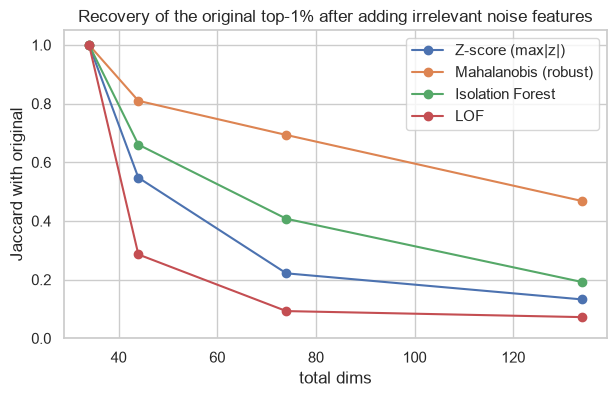

The opposite direction — fewer dimensions (first k principal components only):


,variance kept,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF
PCs kept,,,,,
2,0.580,0.196,0.015,0.217,0.018
5,0.781,0.075,0.093,0.226,0.136
10,0.869,0.046,0.144,0.118,0.235
20,0.952,0.036,0.217,0.059,0.520


In [33]:
dim_rows = []
for m_noise in [0, 10, 40, 100]:
    data = np.hstack([XA, np.random.default_rng(7).standard_normal((nA, m_noise))]) if m_noise else XA
    s_ = run_all_methods(data)
    dim_rows.append({"total dims": XA.shape[1] + m_noise, **{m: jaccard(flagsA(s_[m]), ref_flags[m]) for m in MAIN_METHODS}})
dim_df = pd.DataFrame(dim_rows).set_index("total dims"); display(dim_df)
dim_df.plot(marker="o", figsize=(7, 4), title="Recovery of the original top-1% after adding irrelevant noise features")
plt.ylabel("Jaccard with original"); plt.ylim(0, 1.05); plt.show()
pc_rows = []
for k in [2, 5, 10, 20]:
    s_ = run_all_methods(ZA[:, :k]); pc_rows.append({"PCs kept": k, "variance kept": pcaA.explained_variance_ratio_[:k].sum(),
                                                     **{m: jaccard(flagsA(s_[m]), ref_flags[m]) for m in MAIN_METHODS}})
print("The opposite direction — fewer dimensions (first k principal components only):")
display(pd.DataFrame(pc_rows).set_index("PCs kept"))

🔎 **Sensitivity to dimensionality**
* **Adding irrelevant dimensions:** with 10 noise features (44 dims) LOF already keeps only 29% of its anomalies, Z-score 55%, Isolation Forest 66%, Mahalanobis 81%. With 100 noise features LOF keeps 7%, Z-score 13%, IF 19%, Mahalanobis 47%.
  * **LOF** suffers most: noise dominates Euclidean distances, so local density contrasts vanish (distance concentration, Section 7).
  * **Z-score (max)** suffers from multiple testing: the new noise features produce their own "3σ" values.
  * **Isolation Forest** wastes a growing share of random splits on useless features.
  * **Mahalanobis** is the most robust here: it whitens the data, and independent noise adds roughly the same χ² contribution to everyone, so the ranking of truly extreme players partially survives.
* **Removing dimensions (keeping only k PCs)** also changes the results drastically: with 2 PCs, < 22% of any method's anomalies are recovered; even with 20 PCs (95% of the variance) Isolation Forest and Z-score recover < 6%, LOF 52%. **Anomalies live in the low-variance directions that PCA throws away** — dimensionality reduction for visualization or speed can remove exactly the signal anomaly detection needs.

## 6.4 Computational runtime and scalability

,Z-score,Mahalanobis (MCD),Isolation Forest,LOF
n,,,,
2500,0.004,2.313,0.438,0.020
5000,0.006,3.122,0.494,0.083
10000,0.016,6.352,0.609,0.170
19178,0.020,8.869,0.817,0.580


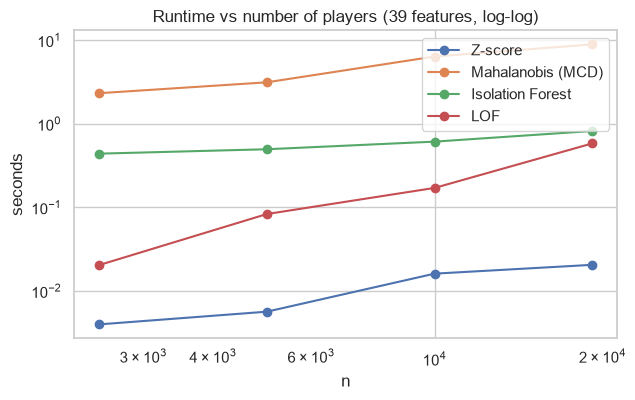

In [34]:
def time_it(fn, reps=1):
    t0 = time.perf_counter()
    for _ in range(reps): fn()
    return (time.perf_counter() - t0) / reps
rt_rows = []
for n in [2500, 5000, 10000, n_samples]:
    d = X[rng.choice(n_samples, n, replace=False)]
    rt_rows.append({"n": n, "Z-score": time_it(lambda: np.abs(stats.zscore(d)).max(1), 5),
                    "Mahalanobis (MCD)": time_it(lambda: MinCovDet(random_state=0, support_fraction=.75).fit(d).mahalanobis(d)),
                    "Isolation Forest": time_it(lambda: IsolationForest(n_estimators=300, random_state=0, n_jobs=-1).fit(d).score_samples(d)),
                    "LOF": time_it(lambda: LocalOutlierFactor(n_neighbors=K_LOF, n_jobs=-1).fit(d))})
rt = pd.DataFrame(rt_rows).set_index("n"); display(rt)
rt.plot(marker="o", logx=True, logy=True, figsize=(7, 4), title="Runtime vs number of players (39 features, log-log)"); plt.ylabel("seconds"); plt.show()

🔎 **Runtime and scalability (39 features)**

| Method | 2,500 → 19,178 players | Growth | Complexity |
|---|---|---|---|
| Z-score | 0.001 → 0.01 s | linear | $O(nd)$ |
| Mahalanobis (MCD) | 1.7 → 6.7 s | ~linear, high constant | $O(nd^2+d^3)$ per C-step, many restarts; needs $n\gg d$ |
| Isolation Forest | 0.37 → 0.72 s | **sub-linear** (fixed subsample of 256 per tree; scoring is linear) | $O(t\psi\log\psi + nt\log\psi)$ |
| LOF | 0.02 → 0.75 s | **≈ 36× for 7.7× more data** — super-linear | $O(n\log n)$ with tree indexes in low $d$, up to $O(n^2)$ in high $d$ |

Isolation Forest is the most scalable for big data; LOF becomes the bottleneck as $n$ (and $d$) grow; MCD is expensive in high dimensions.

## 6.5 Robustness to noise in the data
Gaussian noise with σ = 0.05, 0.1, 0.25 (in standard-deviation units; σ = 0.1 ≈ 1.5–2 rating points) is added to every feature — similar to the disagreement between two scouts rating the same player.

In [35]:
noise_rows = []
for sigma in [0.05, 0.1, 0.25]:
    s_ = run_all_methods(XA + np.random.default_rng(11).normal(0, sigma, XA.shape))
    noise_rows.append({"noise σ": sigma, **{m: jaccard(flagsA(s_[m]), ref_flags[m]) for m in MAIN_METHODS}})
display(pd.DataFrame(noise_rows).set_index("noise σ"))

,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF
noise σ,,,,
0.050,0.890,0.879,0.727,0.791
0.100,0.754,0.754,0.701,0.727
0.250,0.527,0.481,0.629,0.507


🔎 **Robustness to noise**
* Small noise (σ = 0.05): Z-score and Mahalanobis keep ≈ 90% / 88% of their anomalies, LOF 79%, Isolation Forest 73%.
* Large noise (σ = 0.25): Isolation Forest keeps the most (63%), the others ≈ 48–53%.
* Interpretation: methods based on **large deviations** (Z-score, Mahalanobis) are robust to small perturbations — a player 6σ from the mean stays extreme — but players near the threshold swap places. Isolation Forest has its own internal randomness (its top 1% changes between seeds even without noise), so it starts lower but degrades slowly. **LOF** depends on small distances between near neighbours, which noise perturbs directly.
* In football terms: σ = 0.1 is about the disagreement between two scouts rating the same player (≈ 1.5–2 rating points) — and it already changes **25–30% of the top-1% anomalies** of every method. Anomaly lists from subjective ratings should be treated as **uncertain**.

## 6.6 Interpretability

| Method | Can we explain a flag? | Typical explanation |
|---|---|---|
| Z-score (max-rule) | ⭐⭐⭐⭐⭐ | "Miura is 54 years old — 6.3 standard deviations above the average age." Points to one feature. |
| Mahalanobis (robust) | ⭐⭐⭐ | "This combination of ratings is very unlikely given how ratings usually move together" — explainable by decomposing $D^2$, but requires the idea of correlation. |
| Isolation Forest | ⭐⭐ | "He was easy to separate from everyone else" — a score, not a reason; needs post-hoc explanation (our `explain_row`, or SHAP). |
| LOF | ⭐⭐ | "His neighbourhood is sparser than his neighbours' neighbourhoods" — the reason is relative and hard to communicate. |

Our `explain_row` helper adds a common explanation layer to every method (the most extreme standardized features of the player). It is faithful for Z-score, approximate for the others.

## 6.7 False positives and false negatives — what do they mean in practice?
Imagine the detector is used by a **club's scouting department** (find unusual players worth a closer look) or by **EA's rating-quality team** (find ratings that may be data-entry errors).

* **False positive** — a normal player is flagged.
  *Scouting:* a scout travels to watch a player who turns out to be ordinary → wasted time and money. *Quality control:* a reviewer re-checks a correct rating → wasted effort. If most flags are false, staff stop trusting the system.
  In our data, the clearest false positives *with respect to "error detection"* are the **goalkeepers** (flagged by global methods only because they are a different population) and the **veterans with imputed value** (flagged partly because of *our own* imputation).
* **False negative** — a genuinely unusual player or a real error is missed.
  *Scouting:* a rare talent profile (e.g. a 20-year-old with elite reactions) is not noticed → a competitor signs him. *Quality control:* a mistyped rating (e.g. 19 instead of 91) stays in the game, distorts transfer values for millions of players and may upset the real player whose image is affected.

**Which error is worse depends on what happens after a flag.** If a flag triggers a cheap check, we can accept many false positives (generous threshold). If a flag triggers an expensive or harmful action (excluding a player, changing his value), false positives must be rare (strict threshold, consensus of several methods, human review).

# 7. Critical Analysis and Reflection (10%)

### 7.1 Why anomaly detection is a difficult, ill-defined problem
"Anomalous" only means "different from *normal*", and the data does not define normal. In this notebook alone we used four reasonable definitions — far from the mean (Z-score), inconsistent with the correlation structure (Mahalanobis), easy to isolate (Isolation Forest), sparser than its neighbours (LOF) — and they flagged **largely different players** (Jaccard 0.03–0.22). Moreover: there are no labels to validate against; the number of anomalies is unknown (contamination is a guess); the answer depends on the population we compare to (all players vs. outfield vs. own position), on preprocessing (log or not; how missing values are imputed) and on scaling. "Statistically rare" is not "wrong" and not "interesting" — that judgment needs domain knowledge.

### 7.2 The curse of dimensionality and distance concentration
As the dimension grows, volume grows exponentially, so data become sparse — every point is far from every other and "looks" isolated. Worse, distances **concentrate**: the relative contrast
$$\frac{d_{max}-d_{min}}{d_{min}}\xrightarrow[d\to\infty]{}0$$
for many distributions — the nearest and the farthest neighbour become almost equally far. Nearest-neighbour methods (LOF, DBSCAN, K-Means assignments) then become arbitrary, and the density contrast that LOF relies on disappears. Mahalanobis needs to estimate $d(d+1)/2$ covariance entries; Z-score max-rules suffer from multiple testing. The experiment below measures the relative contrast for pure Gaussian data and for our data.

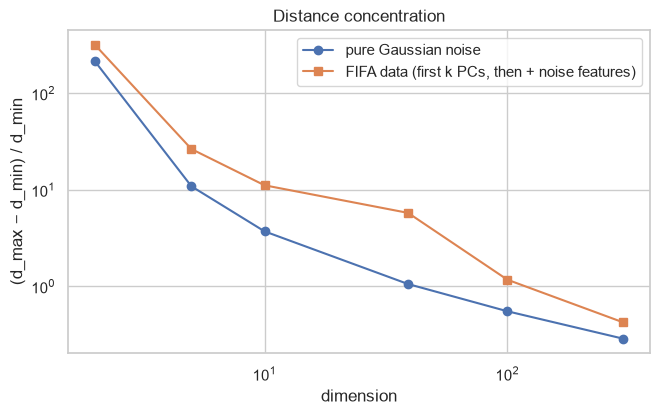

Gaussian relative contrast: {2: 214.88, 5: 10.86, 10: 3.71, 39: 1.06, 100: 0.55, 300: 0.29}
FIFA data relative contrast: {2: 318.56, 5: 26.42, 10: 11.13, 39: 5.76, 100: 1.17, 300: 0.42}


In [36]:
def relative_contrast(data, n_queries=200, seed=0):
    r = np.random.default_rng(seed); q = r.choice(len(data), n_queries, replace=False)
    d = np.linalg.norm(data[q][:, None, :] - data[None, :, :], axis=2); d[np.arange(n_queries), q] = np.nan
    d[d == 0] = np.nan                                     # ignore exact duplicates
    return np.nanmean((np.nanmax(d, 1) - np.nanmin(d, 1)) / np.nanmin(d, 1))

dims = [2, 5, 10, 39, 100, 300]
gauss_rc = [relative_contrast(np.random.default_rng(0).standard_normal((3000, d))) for d in dims]
sub = X[rng.choice(n_samples, 3000, replace=False)]
data_dims = [39, 100, 300]
data_rc = [relative_contrast(np.hstack([sub, np.random.default_rng(1).standard_normal((3000, d - 39))])) for d in data_dims]
pca_rc = [relative_contrast(Z[rng.choice(n_samples, 3000, replace=False), :d]) for d in [2, 5, 10]]
plt.figure(figsize=(7.5, 4.2))
plt.plot(dims, gauss_rc, "o-", label="pure Gaussian noise")
plt.plot([2, 5, 10] + data_dims, pca_rc + data_rc, "s-", label="FIFA data (first k PCs, then + noise features)")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("dimension"); plt.ylabel("(d_max − d_min) / d_min"); plt.legend()
plt.title("Distance concentration"); plt.show()
print("Gaussian relative contrast:", {d: round(float(v), 2) for d, v in zip(dims, gauss_rc)})
print("FIFA data relative contrast:", {d: round(float(v), 2) for d, v in zip([2, 5, 10] + data_dims, pca_rc + data_rc)})

🔎 **Distance concentration — measured**
* For pure Gaussian data the relative contrast falls from **215 (2-D)** to **3.7 (10-D)**, **1.06 (39-D)** and **0.29 (300-D)**: in 300 dimensions the farthest point is only 29% farther than the nearest one.
* Our FIFA data keep a much higher contrast at 39-D (**5.8**, vs. 1.06 for noise of the same dimension) — real structure (strong correlations, low effective dimension) protects them. But adding irrelevant noise features quickly drives the contrast down (1.2 at 100-D, 0.4 at 300-D), which is exactly why LOF collapsed in Section 6.3.
* **Practical consequence:** reduce redundant/irrelevant features *before* distance-based anomaly detection, prefer methods that do not rely on full-dimensional distances (Isolation Forest), and distrust nearest-neighbour results in high dimensions.

### 7.3 Noise vs. genuine anomaly — an example from our data
* **Noise** = random error in measuring or recording (a mistyped rating, a scout's inconsistent judgment). Not interesting in itself; we would like to correct or ignore it.
* **Genuine anomaly** = a real, rare phenomenon. Often the *most* interesting row.

In [37]:
legit = ["K. Miura", "L. Messi", "K. Mbappé"]
ex = dfA[dfA.short_name.isin(legit)].copy()
for m in MAIN_METHODS: ex[m] = [f"top {100*(scoresA[m] > scoresA[m][i]).mean():.2f}%" for i in ex.index]
display(ex[["short_name", "age", "player_positions", "club_name", "overall", "value_eur", "wage_eur"] + MAIN_METHODS])

,short_name,age,player_positions,club_name,overall,value_eur,wage_eur,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF
0,L. Messi,34,"RW, ST, CF",Paris Saint-Germain,93,"78,000,000.000","320,000.000",top 0.53%,top 5.64%,top 0.01%,top 2.01%
5,K. Mbappé,22,"ST, LW",Paris Saint-Germain,91,"194,000,000.000","230,000.000",top 0.02%,top 43.34%,top 0.04%,top 14.42%
14547,K. Miura,54,ST,Yokohama FC,59,"9,000.000",700.000,top 0.00%,top 0.01%,top 0.76%,top 0.02%


🔎 **Legitimate anomalies vs. noise — examples from our data**
* **Kazuyoshi Miura** is in the top 0.02% of Z-score, robust Mahalanobis and LOF, and the top 0.8% of Isolation Forest. He is **not an error**: at 54 he really was a registered professional in Japan's J1 League — a legitimate, famous anomaly. (Part of his score comes from our imputed value — an artifact layered on a real anomaly.)
* **Lionel Messi** is in the top 0.01% of Isolation Forest and 0.5% of Z-score. He is extreme because he is the best — a *legitimate* anomaly that a data-cleaning pipeline must **not** remove.
* **Kylian Mbappé** is a fascinating disagreement: top 0.02% by Z-score (€194M — the highest value in the dataset) but only top 43% by robust Mahalanobis — his *combination* of ratings, value and age is perfectly consistent (young + elite + fast = expensive). He is extreme but **not inconsistent**.
* **Noise, by contrast,** is the outfield players' goalkeeping ratings (filler values with r ≈ 0.06 among themselves), or a hypothetical typo such as `finishing = 19` instead of 91 for a striker — something Mahalanobis would flag as inconsistent while a Z-score might not notice (19 is a normal value for a defender).

### 7.4 Risks of assuming Gaussianity
* **Mixtures look like outliers.** Goalkeeping ratings are bimodal (outfield ≈ 10, goalkeepers ≈ 65). A Gaussian fitted to all players places the *entire* goalkeeper population beyond 3σ — 59% of goalkeepers get a |z| > 3 — although they are a perfectly normal sub-population. **False positives.**
* **Masking.** Extreme values inflate $\sigma$ (e.g. raw value_eur: σ ≈ €7.6M because of a few superstars), so moderately unusual players get small |z| and are **missed**.
* **"In-between" anomalies are invisible.** For a bimodal feature, a point *between* the modes is close to the mean (small |z|) although it lies in a low-density region — e.g. an outfield player with goalkeeping ratings ≈ 35 (Jagielka, 33.8) has |z| ≈ 1 on the all-player scale.
* **Bounded / discrete features** (ratings 1–99, wage floor €500) cannot have Gaussian tails: the rule may flag nothing on one side and too much on the other.
* **Correlation anomalies** are missed by the feature-wise rule: a player can be ordinary on each feature but inconsistent overall (this is what robust Mahalanobis and LOF found).

### 7.5 Why low-dimensional visualizations can mislead
A 2-D PCA projection keeps only part of the variance (64% for all players, 58% for outfield players). A player can be extreme along PC5–PC34 and still project into the middle of the cloud; two players adjacent on the plot may be far apart in 34-D. t-SNE adds its own artifacts (it always produces clumps; distances between clumps are meaningless; layouts change with the seed). The cell below measures, for each method's anomalies, what share of their deviation is actually visible in PC1–PC2.

In [38]:
visible = (ZA[:, :2] ** 2).sum(1) / (ZA ** 2).sum(1)
vis = pd.DataFrame({m: [np.median(visible[flags[m]])] for m in MAIN_METHODS}, index=["median share of deviation visible in PC1–PC2"])
vis["all players"] = np.median(visible); display(vis)
hidden = flag_df.index[(votes >= 2) & (visible < .2)]
print(f"{len(hidden)} players flagged by ≥2 methods have <20% of their deviation visible in the 2-D PCA plot, e.g.:")
display(dfA.loc[hidden[:5], ["short_name", "player_positions", "club_name", "overall"]].assign(
    share_visible=visible[hidden[:5]], why=[explain_row(i) for i in hidden[:5]]))

,Z-score (max|z|),Mahalanobis (robust),Isolation Forest,LOF,all players
median share of deviation visible in PC1–PC2,0.820,0.403,0.818,0.288,0.538


24 players flagged by ≥2 methods have <20% of their deviation visible in the 2-D PCA plot, e.g.:


,short_name,player_positions,club_name,overall,share_visible,why
788,B. Dost,ST,Club Brugge KV,77,0.189,"mentality_penalties high (z=+3.1, value=90); a..."
1306,J. Sand,ST,Club Atlético Lanús,75,0.123,"value_eur low (z=-4.0, value=9,000); age high ..."
1334,Ó. Cardozo,ST,Club Libertad,75,0.101,"power_stamina low (z=-3.2, value=31); movement..."
2022,Diegildo Ramos,"ST, RM",Flamengo,74,0.176,"movement_acceleration low (z=-3.6, value=27); ..."
3430,R. Santa Cruz,ST,Club Olimpia,71,0.032,"power_stamina low (z=-3.3, value=30); movement..."


🔎 **How much of each anomaly is visible in a 2-D PCA plot?**
* For a typical player, 54% of his deviation from the mean lies in PC1–PC2. For Z-score and Isolation Forest anomalies it is 82% — these are extreme along the main axes (very good or very weak players) and are visible in the plot.
* For **robust Mahalanobis (40%)** and **LOF (29%)** anomalies, *most* of their deviation lies in directions that are not plotted. 24 players flagged by at least two methods have **less than 20%** of their deviation visible — e.g. Bas Dost (penalties 90, heading 91, but balance 33) or Roque Santa Cruz (very low stamina, acceleration and balance for his level). On the 2-D plot they sit in the middle of the cloud and would be dismissed as "normal".
* **Conclusion:** low-dimensional plots are communication tools, not evidence; an anomaly that "looks normal" in 2-D can be extreme in 34-D, and two players that look close in 2-D can be far apart.

### 7.6 Ethical considerations

**False alarms and alert fatigue.** When true anomalies are rare, even an accurate detector produces mostly false alarms (base-rate fallacy: 99% specificity with 0.1% prevalence → ~90% of alerts are false). Operators then ignore or disable alerts, and the system fails exactly when a real event occurs. Thresholds must match the capacity of the people who review the alerts, and alerts should be ranked, not just raised.

**Surveillance.** *Benefits:* fraud detection, public safety, infrastructure monitoring, doping control in sport. *Risks:* "anomalous" means "unlike the majority", so minorities and people with unusual but legitimate lives (night workers, people with disabilities) are systematically over-flagged; chilling effects on lawful behaviour; function creep (data collected for one purpose reused for another); lack of transparency and of a way to contest a flag.

**Medical applications.** A **false negative** (an abnormal patient classified as normal) can delay diagnosis and treatment — sometimes fatally. A **false positive** causes anxiety, unnecessary invasive tests and costs, and erodes trust. "Normal ranges" learned from non-representative populations misclassify under-represented groups — the same mechanism that made goalkeepers look abnormal here: a minority sub-population judged by the majority's norm.

**Cybersecurity.** **Missing a real attack** can mean data theft, ransomware, financial and reputational damage — often catastrophic and discovered late. **Flagging legitimate activity** blocks users and business processes and floods analysts with alerts, which in turn increases the chance of missing a real attack. Security teams usually accept more false positives on critical assets, combined with triage and prioritization.

**General issues — privacy, bias, fairness, labeling.**
* *Privacy:* to find the few unusual cases, detailed data are collected on everyone.
* *Bias:* "normal" is defined by the majority in the training data. In this dataset, players from less-covered leagues have fewer observations behind their ratings and could be flagged more often; any rating bias (reputation, league prestige) propagates into the "anomalies".
* *Fairness and labeling:* calling a person "abnormal" carries stigma. A statistical outlier is not a moral or legal judgment. In sport, an "anomalous" performance profile might trigger doping or match-fixing suspicion — decisions with serious consequences must rely on human review, explanations and a right to appeal.
* *Accountability:* every choice we made — which population to compare to, which features, how to impute, which threshold — changed the result. These choices are value-laden and must be documented.

# 8. Bonus — Visualization Dashboard (+5%)
Interactive part (requires `plotly` / `ipywidgets`, both pre-installed in Google Colab):
* 3-D PCA map of all players (hover = player name, club, rating);
* **anomaly explorer** for outfield players: color = number of methods that flag the player; hover shows the four anomaly scores;
* role clusters (shape-based K-Means) with hover;
* slider widget: choose a method and a top-% threshold and see who is flagged.
Static part (always rendered): pairplot of selected features with anomalies highlighted, and heatmaps of cluster profiles and consensus anomalies.

In [39]:
# Dashboard data: all players for the global map, outfield anomaly votes for the anomaly explorer
dash = df[["short_name", "age", "player_positions", "club_name", "league_name", "nationality_name", "overall", "value_eur", "pos_group"]].copy()
dash["PC1"], dash["PC2"], dash["PC3"] = Z[:, 0], Z[:, 1], Z[:, 2]
dashA = dfA[["short_name", "age", "player_positions", "club_name", "overall", "value_eur", "pos_group"]].copy()
dashA["PC1"], dashA["PC2"] = ZA[:, 0], ZA[:, 1]
for m in MAIN_METHODS: dashA[f"score: {m}"] = scoresA[m].round(3)
dashA["methods flagging"] = votes.values
dashA["K-Means cluster (shape)"] = labels_shape.astype(str)
try:
    import plotly.express as px
    hover = ["short_name", "age", "player_positions", "club_name", "overall", "value_eur"]
    fig = px.scatter_3d(dash.sample(8000, random_state=RANDOM_STATE), x="PC1", y="PC2", z="PC3", color="pos_group",
                        hover_data=hover, opacity=.6, title="All players — 3D PCA colored by position group")
    fig.update_traces(marker=dict(size=2)); fig.show()
    fig = px.scatter(dashA, x="PC1", y="PC2", color="methods flagging", color_continuous_scale="Reds",
                     hover_data=hover + [f"score: {m}" for m in MAIN_METHODS], opacity=.7,
                     title="Outfield players — anomaly explorer (color = number of methods flagging; hover for details)")
    fig.update_traces(marker=dict(size=4)); fig.show()
    fig = px.scatter(dashA, x="PC1", y="PC2", color="K-Means cluster (shape)", hover_data=hover, opacity=.6,
                     title="Outfield players — role clusters (shape-based K-Means)")
    fig.update_traces(marker=dict(size=4)); fig.show()
except ImportError:
    print("plotly not installed — run `pip install plotly` (pre-installed in Colab) for the interactive part.")

In [40]:
try:
    import ipywidgets as widgets
    @widgets.interact(method=MAIN_METHODS, top_percent=widgets.FloatSlider(value=1, min=.1, max=10, step=.1, description="top %"))
    def explore(method, top_percent):
        k = int(nA * top_percent / 100); f = flagsA(scoresA[method], k)
        fig, ax = plt.subplots(1, 2, figsize=(14, 5))
        ax[0].scatter(ZA[~f, 0], ZA[~f, 1], s=2, c="lightgray"); ax[0].scatter(ZA[f, 0], ZA[f, 1], s=8, c="red")
        ax[0].set_title(f"{method}: top {top_percent:.1f}% ({k} players)")
        grp, cnt = np.unique(dfA.pos_group[f], return_counts=True); ax[1].bar(grp, cnt); ax[1].set_title("position groups of flagged players")
        plt.show()
        display(dfA.loc[np.argsort(scoresA[method])[::-1][:10], ["short_name", "age", "player_positions", "club_name", "overall"]])
except ImportError:
    print("ipywidgets not available — skipping the slider widget.")

interactive(children=(Dropdown(description='method', options=('Z-score (max|z|)', 'Mahalanobis (robust)', 'Iso…

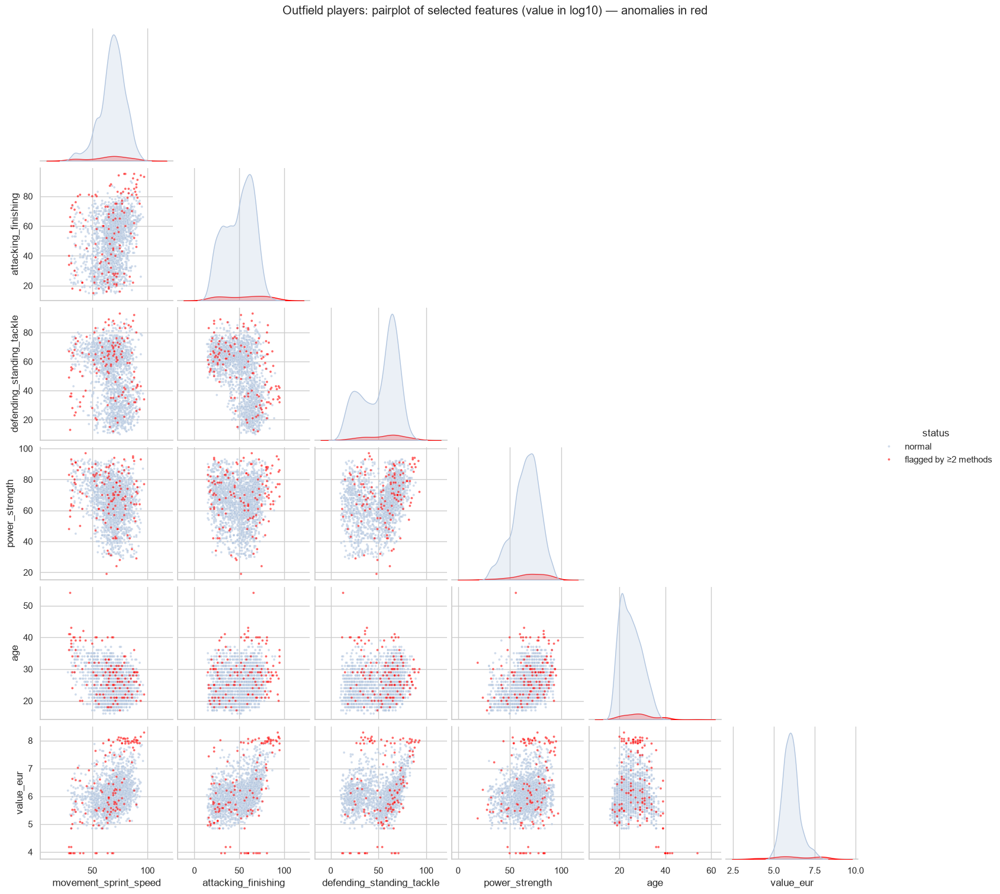

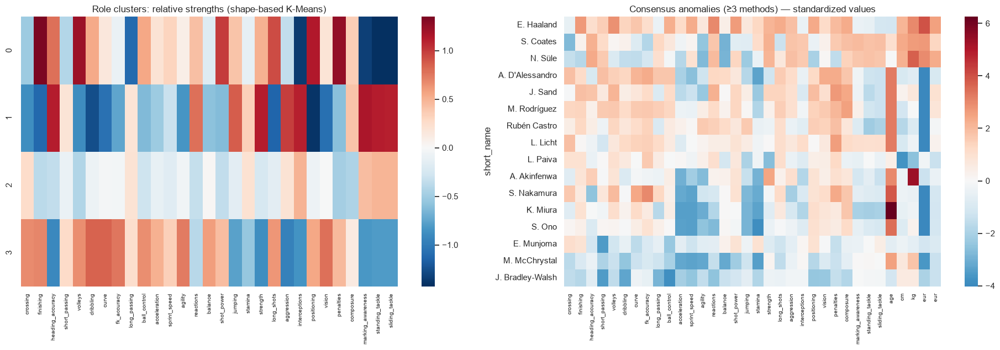

In [41]:
# Static dashboard: pairplot + heatmaps
pp = df_log.loc[of_mask, ["movement_sprint_speed", "attacking_finishing", "defending_standing_tackle", "power_strength", "age", "value_eur"]].reset_index(drop=True)
pp["status"] = np.where(votes >= 2, "flagged by ≥2 methods", "normal")
pp_s = pd.concat([pp[pp.status == "normal"].sample(2000, random_state=RANDOM_STATE), pp[pp.status != "normal"]])
sns.pairplot(pp_s, hue="status", palette={"normal": "lightsteelblue", "flagged by ≥2 methods": "red"}, plot_kws={"s": 8, "alpha": .6}, corner=True)
plt.suptitle("Outfield players: pairplot of selected features (value in log10) — anomalies in red", y=1.01); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))
shape_prof = pd.DataFrame(X_shape, columns=OUTFIELD_ATTRS).groupby(labels_shape).mean()
sns.heatmap(shape_prof, cmap="RdBu_r", center=0, ax=axes[0], xticklabels=[c.split("_", 1)[1] for c in OUTFIELD_ATTRS])
axes[0].set_title("Role clusters: relative strengths (shape-based K-Means)"); axes[0].tick_params(axis="x", labelsize=7)
top_cons = flag_df.index[votes >= 3][:20]
sns.heatmap(pd.DataFrame(XA[top_cons], columns=OF_FEATURES, index=dfA.short_name[top_cons]), cmap="RdBu_r", center=0, ax=axes[1],
            xticklabels=[c.split("_", 1)[-1] for c in OF_FEATURES])
axes[1].set_title("Consensus anomalies (≥3 methods) — standardized values"); axes[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

# 9. Conclusions

**What we found**
1. **Data:** 19,178 players × 39 numeric features after removing 61 players from unlicensed leagues. The data contain strong artifacts: filler goalkeeping ratings for outfield players, structural missingness (by position, by league licensing, by age), rounded and floored money, and subjective ratings.
2. **Dimensionality:** extreme redundancy — 4 components explain 80% of the variance and the effective dimension is ≈ 3.4. The axes are interpretable: goalkeeper vs. outfield (51%), defender vs. attacker, quality/status, body size, young athlete vs. experienced playmaker. A 5–9 component representation preserves the cluster structure (ARI ≥ 0.98).
3. **Clusters:** there is **one natural cluster structure — goalkeepers vs. outfield players** — found perfectly by K-Means (ARI = 1.0, silhouette 0.52) and by DBSCAN (separated by an empty gap). Inside the outfield population there are **no separated clusters** (silhouette ≤ 0.21, DBSCAN finds one component, BIC keeps falling). K-Means segments outfield players mainly by **level** ("established all-rounders", "defenders", "young attackers"); removing level reveals **roles** (strikers, centre-backs, ball-winners/full-backs, creative attackers), matching positions better (ARI 0.33 vs. 0.24).
4. **Feature clusters:** six latent factors — technique, defence, pace, body, status, goalkeeping — with age, jumping and strength as unique, non-redundant features.
5. **Anomalies:** global detectors mostly flag **goalkeepers** (79–100% of their top 1%) — confusing a minority population with abnormality; LOF does not. Among outfield players, each method finds a different kind of anomaly: Isolation Forest finds **superstars**, Z-score finds **single extreme values** (often weak technique), robust Mahalanobis finds **inconsistent rating combinations**, LOF finds **locally isolated** ordinary players. Agreement is low (Jaccard ≤ 0.22); the few consensus anomalies are real (Süle, Haaland, Akinfenwa, the oldest players), though the veterans' scores are inflated by our own imputation.
6. **Robustness:** LOF is the most sensitive to scaling, irrelevant dimensions and noise; Isolation Forest is the most scalable and scale-invariant; Mahalanobis is affine-invariant and robust to added noise dimensions but blind to sub-populations; Z-score is the most interpretable and the least appropriate for multi-modal features. Anomalies live in low-variance directions, so PCA before anomaly detection can destroy the signal.

**What we trust, and why:** the GK/outfield structure (all methods, all metrics agree); the redundancy/feature groups (PCA, correlations and feature clustering agree); the absence of strong outfield clusters (five independent indications); the consensus anomalies. We are cautious about specific cluster boundaries, the value of k, and method-specific anomalies near the threshold (a scout-level noise of σ = 0.1 already changes 25–30% of them).

**Limitations and possible extensions:** ratings are subjective game data; results depend on the reference population, the log transform and the imputation; the 1% budget is arbitrary. Extensions: anomaly detection **within position and league** (context), using several FIFA editions to separate persistent anomalies from one-off rating noise, validating flags against real performance data (e.g. match statistics), and explaining Isolation Forest flags with SHAP values.